# Notebook 03. TBscreen (Kenya): baselines, shift analyses and comparison with Zambia

**Why this notebook.** Our study asks whether cough audio adds value to a short clinical questionnaire when recording conditions change. While CODA access is pending, TBscreen (Nairobi, Kenya; Sharma et al., *Science Advances* 2024) gives us a second country. Together with Zambia it lets us study shift along four axes: **device**, **cough type**, **clinic** (Zambia only) and **country**.

**What it does, in order.**

| Step | Question | Output |
|---|---|---|
| 1 | Where is everything in the Azure container? | Folder map and key files |
| 2 | Who are the participants and what was measured? | Harmonised clinical table |
| 3 | How does Kenya compare with Zambia? | EDA figures and a side-by-side table |
| 4 | Did the three devices record the same coughs? | Pairing statistics |
| 5 | Get the cough features without downloading 795 GB | VGGish spectrograms, verified against raw audio |
| 6 | Turn spectrograms into embeddings | Pretrained VGGish embeddings |
| 7 | Baselines on the paper's own folds | Questionnaire, audio, fusion and $\Delta$; fine-tuned VGGish reproduction |
| 8 | Is the feature space organised by device? | Probes, map, same-cough distances, unseen device |
| 9 | Do natural and forced coughs transfer? | Cough-type transfer matrix |
| 10 | Does a model travel between Zambia and Kenya? | Within versus across-country results |
| 11 | Save everything | Tables, figures and a results bundle |

**Kaggle settings.**
* **Accelerator: GPU T4.** Only Steps 6, 7b and 10 benefit; everything else is CPU.
* **Internet: ON** (Azure access and the VGGish weights).
* **Secrets:** `AZURE_STORAGE_CONNECTION_STRING`, the same secret used for the upload notebook.
* **Add data:** (1) the TBscreen code folder, for the published folds `Figures/datacsv/folds/T1_*.csv`; (2) the Zambia export bundles from Notebook 01 (`zambia_features_mel`, `zambia_segmented_coughs`, `zambia_metadata_cohort`). Both are found automatically.

**How it saves time.** TBscreen ships precomputed VGGish input spectrograms (in a folder confusingly named `Vggish_embeddings`), one small file per cough. We download only those for the coughs we use, roughly 0.5 GB, and never touch the scalogram folders that make up most of the 795 GB. Downloads are cached, so re-running is fast.

In [1]:
import os, io, re, sys, json, time, copy, zipfile, itertools, subprocess, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import soundfile as sf, librosa
from scipy.stats import norm
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve, balanced_accuracy_score
from sklearn.manifold import TSNE
from IPython.display import display
warnings.filterwarnings("ignore")

TEST_MODE = os.environ.get("TB_TEST_MODE") == "1"
CFG = dict(
    # where the data lives
    AZURE_CONTAINER   = "tbscreen",
    AZURE_PREFIX      = "v1/",
    LOCAL_STORE       = None,        # a folder that mirrors the container (offline testing only)
    FOLDS_DIR         = None,        # None = search /kaggle/input for Figures/datacsv/folds/T1_0.csv
    ZAMBIA_INPUT      = "/kaggle/input/datasets/martinkoome/zambia-outputs",        # None = search /kaggle/input for the Notebook 01 bundles
    WORK_DIR          = "/kaggle/working",
    # what to load
    PASSIVE_SCOPE     = "T1",        # "T1" = the paper's 90 balanced participants; "all" = every passive cough
    LOAD_FORCED       = True,
    SAMPLE_FRACTION   = 1.0,         # share of each participant's coughs to use (1.0 = all); every participant is kept
    MAX_PER_PARTICIPANT_DEVICE = None,   # optional hard cap per participant and device (None = no cap)
    FEATURE_SOURCE    = "provided",  # "provided" = TBscreen's stored spectrograms; "audio" = recompute from wav
    N_AUDIO_CHECK     = 40,          # coughs used to verify the stored spectrograms against raw audio
    DOWNLOAD_WORKERS  = 32,
    # models
    PROBE_C           = 0.1,         # regularisation of the linear probes on embeddings
    CLIN_C            = 1.0,         # regularisation of the questionnaire model
    RUN_FINETUNE      = True,        # fine-tune VGGish on T1 folds (GPU recommended)
    FT_EPOCHS         = 30, FT_PATIENCE = 6, FT_MIN_EPOCHS = 5, FT_BATCH = 32,
    FT_LR_HEAD        = 1e-4, FT_LR_BACKBONE = 1e-5, FT_FOLDS = [0, 1, 2, 3, 4],
    N_BOOT            = 1000,
    MAX_MISSINGNESS_GAP = 0.20,      # drop a clinical variable if its missingness differs by more than this between TB groups
    SEED              = 42,
)
if TEST_MODE:
    CFG.update(LOCAL_STORE="/home/claude/tbs/fixtures/fake_azure", FOLDS_DIR="/home/claude/tbs/fixtures/tbscreen_code",
               ZAMBIA_INPUT="/home/claude/tbs/fixtures/zambia_export", WORK_DIR="/home/claude/tbs/work",
               N_AUDIO_CHECK=12, N_BOOT=200, FT_EPOCHS=2, SAMPLE_FRACTION=0.6)

WORK = Path(CFG["WORK_DIR"]); OUT = WORK / "outputs_tbscreen"; CACHE = WORK / "cache_tbscreen"; FIG_DIR = OUT / "figures"
for d in (OUT, CACHE, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(CFG["SEED"])
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

_original_show, _fig_no = plt.show, [0]
def _show_and_save(*args, **kwargs):                      # every figure shown is also saved for the report
    for num in plt.get_fignums():
        fig = plt.figure(num)
        title = fig._suptitle.get_text() if getattr(fig, "_suptitle", None) else (fig.axes[0].get_title() if fig.axes else "")
        _fig_no[0] += 1
        slug = re.sub(r"[^a-z0-9]+", "_", title.lower()).strip("_")[:60] or "figure"
        fig.savefig(FIG_DIR / f"{_fig_no[0]:02d}_{slug}.png", dpi=150, bbox_inches="tight")
    _original_show(*args, **kwargs)
plt.show = _show_and_save

try:
    import torch, torch.nn as nn
    TORCH_OK, DEVICE = True, ("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(CFG["SEED"])
except ImportError:
    TORCH_OK, DEVICE = False, "cpu"
print(f"Test mode: {TEST_MODE} | PyTorch: {TORCH_OK} | device: {DEVICE}")

Test mode: False | PyTorch: True | device: cuda


## Step 1. Connect to the data and map its layout

**What we do.** Open the Azure container through a small storage wrapper, then walk the folder tree to find the key files: `Metadata.csv`, `Dataset_key.csv`, the passive and forced cough tables, and for each cough type its `Audio_files` and VGGish-spectrogram folders. Names are matched loosely (case, spaces and underscores ignored), because the README and the code spell them differently.

**Why a wrapper.** The same notebook then runs against Azure on Kaggle and against a local folder for offline testing. Folders holding hundreds of thousands of files (audio, scalograms, spectrograms) are located but never listed in full here.

In [2]:
def _norm(s):
    return re.sub(r"[\s_\-]+", "", s.lower())

class LocalStore:
    # A folder that mirrors the container; blob names are paths relative to it.
    def __init__(self, root):
        self.root = Path(root)
    def walk(self, prefix):
        p = self.root / prefix
        dirs = [f"{prefix}{c.name}/" for c in sorted(p.iterdir()) if c.is_dir()] if p.is_dir() else []
        files = {f"{prefix}{c.name}": c.stat().st_size for c in sorted(p.iterdir()) if c.is_file()} if p.is_dir() else {}
        return dirs, files
    def list(self, prefix):
        p = self.root / prefix
        for f in sorted(p.rglob("*")) if p.is_dir() else []:
            if f.is_file():
                yield f.relative_to(self.root).as_posix(), f.stat().st_size
    def get(self, name):
        return (self.root / name).read_bytes()

class AzureStore:
    def __init__(self, conn, container):
        from azure.storage.blob import BlobServiceClient
        self.c = BlobServiceClient.from_connection_string(conn).get_container_client(container)
    def walk(self, prefix):
        dirs, files = [], {}
        for item in self.c.walk_blobs(name_starts_with=prefix, delimiter="/"):
            if item.name.endswith("/"):
                dirs.append(item.name)
            else:
                files[item.name] = item.size
        return dirs, files
    def list(self, prefix):
        for b in self.c.list_blobs(name_starts_with=prefix):
            yield b.name, b.size
    def get(self, name):
        return self.c.download_blob(name, max_concurrency=1).readall()

def azure_connection_string():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("AZURE_STORAGE_CONNECTION_STRING")
    except Exception:
        return os.environ["AZURE_STORAGE_CONNECTION_STRING"]

if CFG["LOCAL_STORE"]:
    STORE = LocalStore(CFG["LOCAL_STORE"])
else:
    try:
        import azure.storage.blob  # noqa: F401
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "azure-storage-blob"], check=True)
    STORE = AzureStore(azure_connection_string(), CFG["AZURE_CONTAINER"])

def fetch_many(names, decode, workers=None, label="files", tries=4):
    # Download many small blobs in parallel; returns {name: decoded or None} and reports failures.
    workers = workers or CFG["DOWNLOAD_WORKERS"]
    out, failed, t0, done = {}, [], time.time(), 0
    def one(n):
        for k in range(tries):
            try:
                return n, decode(STORE.get(n))
            except Exception as exc:
                if k == tries - 1:
                    return n, exc
                time.sleep(1.5 ** k)
    with ThreadPoolExecutor(workers) as pool:
        futs = [pool.submit(one, n) for n in names]
        step = max(1, len(futs) // 10)
        for f in as_completed(futs):
            n, v = f.result(); done += 1
            if isinstance(v, Exception):
                failed.append((n, repr(v))); out[n] = None
            else:
                out[n] = v
            if done % step == 0 or done == len(futs):
                print(f"  {label}: {done:,}/{len(futs):,} in {time.time() - t0:.0f} s", flush=True)
    if failed:
        print(f"  {len(failed)} {label} failed, e.g. {failed[:2]}")
    return out

LEAF_DIRS = {"audiofiles", "scalogramnumpy", "vggishembeddings", "pytorchembeddings"}
def map_layout(prefix, max_depth=5):
    found_dirs, small_files, queue = [], {}, [(prefix, 0)]
    while queue:
        p, d = queue.pop(0)
        dirs, files = STORE.walk(p)
        small_files.update(files)
        for sd in dirs:
            found_dirs.append(sd)
            if _norm(Path(sd.rstrip("/")).name) not in LEAF_DIRS and d < max_depth:
                queue.append((sd, d + 1))
    return found_dirs, small_files

t0 = time.time()
ALL_DIRS, SMALL_FILES = map_layout(CFG["AZURE_PREFIX"])
def find_file(pred):
    hits = sorted(n for n in SMALL_FILES if pred(_norm(Path(n).name)))
    return hits[0] if hits else None
def find_dir(kind, leaf):
    hits = sorted(d for d in ALL_DIRS if _norm(Path(d.rstrip("/")).name) == leaf and kind in _norm(d))
    return hits[0] if hits else None

LAYOUT = {
    "metadata": find_file(lambda n: n == "metadata.csv"),
    "dataset_key": find_file(lambda n: n in ("datasetkey.csv", "datasetkey.xlsx", "datasetkey.xls")),
    "readme": find_file(lambda n: n == "readme.md"),
}
for kind in ("passive", "forced"):
    LAYOUT[f"{kind}_csv"] = find_file(lambda n, k=kind: k in n and n.endswith(".csv"))
    LAYOUT[f"{kind}_audio"] = find_dir(kind, "audiofiles")
    LAYOUT[f"{kind}_vggish"] = find_dir(kind, "vggishembeddings")
print(f"Mapped {len(ALL_DIRS)} folders and {len(SMALL_FILES)} top-level files in {time.time() - t0:.1f} s")
display(pd.DataFrame({"what": list(LAYOUT), "found at": list(LAYOUT.values())}))
OPTIONAL = ("readme", "dataset_key")          # descriptions only; the analysis does not need them
missing = [k for k, v in LAYOUT.items() if v is None and k not in OPTIONAL and (CFG["LOAD_FORCED"] or "forced" not in k)]
assert not missing, f"Not found in the container: {missing}. Check AZURE_PREFIX and the folder names above."
print("\nFolders found (scalogram and audio folders are located, never downloaded):")
for d in ALL_DIRS:
    print("  ", d)

Mapped 13 folders and 5 top-level files in 3.1 s


,what,found at
0,metadata,v1/TBscreen_Dataset/Metadata.csv
1,dataset_key,v1/TBscreen_Dataset/Dataset_key.xlsx
2,readme,v1/TBscreen_Dataset/README.md
3,passive_csv,v1/TBscreen_Dataset/Passive_coughs/Passive_cou...
4,passive_audio,v1/TBscreen_Dataset/Passive_coughs/Audio_files/
5,passive_vggish,v1/TBscreen_Dataset/Passive_coughs/Melspectrog...
6,forced_csv,v1/TBscreen_Dataset/Forced_coughs/Forced_cough...
7,forced_audio,v1/TBscreen_Dataset/Forced_coughs/Audio_files/
8,forced_vggish,v1/TBscreen_Dataset/Forced_coughs/Melspectrogr...



Folders found (scalogram and audio folders are located, never downloaded):
   v1/TBscreen_Dataset/
   v1/TBscreen_Dataset/Forced_coughs/
   v1/TBscreen_Dataset/Passive_coughs/
   v1/TBscreen_Dataset/Forced_coughs/Audio_files/
   v1/TBscreen_Dataset/Forced_coughs/Melspectrogram_numpy/
   v1/TBscreen_Dataset/Forced_coughs/Scalogram_numpy/
   v1/TBscreen_Dataset/Passive_coughs/Audio_files/
   v1/TBscreen_Dataset/Passive_coughs/Melspectrogram_numpy/
   v1/TBscreen_Dataset/Passive_coughs/Scalogram_numpy/
   v1/TBscreen_Dataset/Forced_coughs/Melspectrogram_numpy/Vggish_embeddings/
   v1/TBscreen_Dataset/Forced_coughs/Melspectrogram_numpy/pytorch_embeddings/
   v1/TBscreen_Dataset/Passive_coughs/Melspectrogram_numpy/Vggish_embeddings/
   v1/TBscreen_Dataset/Passive_coughs/Melspectrogram_numpy/pytorch_embeddings/


## Step 2. Participants, clinical variables and the cough tables

**What we do.** Read the metadata and harmonise the nine clinical variables onto exactly the names and scales used for Zambia, following Zhang et al.'s published mapping:

| Our name | TBscreen column | Mapping |
|---|---|---|
| `age` | `age` | years |
| `male` | `gndr_a` | 1 = female, 0 = male in TBscreen, so male = 1 − `gndr_a` |
| `smoker` | `smkr_a` | 1 or 2 → 1 |
| `hiv_pos` | `hiv_infected_a` | 0 / 1 |
| `prev_tb` | `prev_tb` | 1 or 2 → 1 |
| `cough_days` | `cough_drtn` | weeks × 7 |
| `fever`, `weight_loss`, `night_sweats` | `fever`, `un_wght_loss`, `nght_swts` | 0 / 1 |

**Check this.** The data key below prints TBscreen's own description of each column, so the coding of sex in particular can be confirmed by eye.

**A trap we guard against.** In TBscreen, HIV status is missing for most non-TB participants but few TB patients. A model would learn that "missing" means "no TB", which says nothing about the patient. Any variable whose missingness differs between the two groups by more than 20 percentage points is therefore left out, and the same reduced set is used for Zambia so the countries stay comparable.

Each cough file is then given a **cough key**: the participant plus the cough's number with the device name removed. The same cough recorded on several devices shares one key, which is how devices are paired later. Participant and device come from the table's own columns, because about 5% of file names follow an irregular pattern.

In [3]:
def read_csv_blob(name):
    raw = STORE.get(name)
    for enc in ("utf-8", "utf-8-sig", "cp1252", "latin-1"):        # files saved from Excel are often not UTF-8
        try:
            return pd.read_csv(io.BytesIO(raw), low_memory=False, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"could not decode {name}")

meta_raw = read_csv_blob(LAYOUT["metadata"])
def read_table_blob(name):
    if name.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(io.BytesIO(STORE.get(name)))
    return read_csv_blob(name)

try:
    key_raw = read_table_blob(LAYOUT["dataset_key"]) if LAYOUT["dataset_key"] else None
except Exception as exc:                     # e.g. no Excel reader installed: descriptions are optional
    print("Could not read the data key:", exc); key_raw = None
print(f"Metadata: {meta_raw.shape[0]} rows x {meta_raw.shape[1]} columns")

TB_CLIN_COLS = {"age": "age", "male": "gndr_a", "smoker": "smkr_a", "hiv_pos": "hiv_infected_a", "prev_tb": "prev_tb",
                "cough_days": "cough_drtn", "fever": "fever", "weight_loss": "un_wght_loss", "night_sweats": "nght_swts"}
CLIN_FEATURES = list(TB_CLIN_COLS)
absent = [c for c in TB_CLIN_COLS.values() if c not in meta_raw.columns]
print("Clinical columns missing from Metadata.csv:", absent or "none")
if key_raw is not None:
    kcol = key_raw.columns[0]
    show = key_raw[key_raw[kcol].astype(str).isin(list(TB_CLIN_COLS.values()) + ["Label", "subject"])]
    print("\nTBscreen's own description of the columns we use (confirm the sex coding here):")
    display(show)

num = lambda c: pd.to_numeric(meta_raw.get(c), errors="coerce")
subj_col = "subject" if "subject" in meta_raw.columns else meta_raw.columns[0]
tb_clin = pd.DataFrame({"subject_id": meta_raw[subj_col].astype(str).str.strip()})
tb_clin["label"] = meta_raw["Label"].astype(str).str.strip().str.upper().map({"TB": 1, "NTB": 0, "NON-TB": 0})
tb_clin["age"] = num("age")
tb_clin["male"] = 1 - num("gndr_a")
tb_clin["smoker"] = num("smkr_a").map({0: 0, 1: 1, 2: 1})
tb_clin["hiv_pos"] = num("hiv_infected_a").map({0: 0, 1: 1})
tb_clin["prev_tb"] = num("prev_tb").map({0: 0, 1: 1, 2: 1})
tb_clin["cough_days"] = num("cough_drtn") * 7
tb_clin["fever"] = num("fever").map({0: 0, 1: 1})
tb_clin["weight_loss"] = num("un_wght_loss").map({0: 0, 1: 1})
tb_clin["night_sweats"] = num("nght_swts").map({0: 0, 1: 1})
for extra in ("lab_sptm_xprt_rslt_a", "lab_sptm_smr_rslt_a", "cxr_findings_a___5"):
    if extra in meta_raw.columns:
        tb_clin[extra] = num(extra)
tb_clin = tb_clin.drop_duplicates("subject_id").set_index("subject_id")
print(f"\nParticipants with a TB label: {tb_clin.label.notna().sum()} "
      f"(TB {int((tb_clin.label == 1).sum())}, non-TB {int((tb_clin.label == 0).sum())})")
# Missingness that differs between TB groups is a data-collection artefact, not a symptom: a model would
# learn "missing means no TB". Such variables are left out of every clinical model in this notebook.
miss = tb_clin.groupby("label")[CLIN_FEATURES].apply(lambda g: g.isna().mean()).T
miss.columns = ["missing, non-TB", "missing, TB"]
miss["gap"] = (miss["missing, TB"] - miss["missing, non-TB"]).abs()
CLIN_USE = [c for c in CLIN_FEATURES if miss.loc[c, "gap"] <= CFG["MAX_MISSINGNESS_GAP"] and miss.loc[c].iloc[:2].max() < 0.5]
dropped = [c for c in CLIN_FEATURES if c not in CLIN_USE]
print("Share missing by TB status:"); display((miss * 100).round(0).astype(int).astype(str) + "%")
print(f"Clinical variables used: {CLIN_USE}")
print(f"Left out (missingness differs by TB status or exceeds 50%): {dropped or 'none'}")

DEVICES_TB = ("codec", "pixel", "yeti")
def cough_key(path, subject):
    rest = path[len(subject):] if path.startswith(subject) else path
    return subject + "|" + "_".join(t for t in rest.split("_") if t and t.lower() not in DEVICES_TB)

def load_cough_table(kind):
    t = read_csv_blob(LAYOUT[f"{kind}_csv"])
    t["path"] = t["path"].astype(str).str.replace(r".*[\\/]", "", regex=True).str.replace(r"\.wav$", "", regex=True)
    if "subject" not in t.columns:
        t["subject"] = t.path.str.extract(r"^(PID_\d+[A-Za-z]?)")[0]
    if "device" not in t.columns:
        t["device"] = t.path.str.extract(r"(codec|pixel|yeti)", flags=re.I)[0]
    t["subject_id"] = t.subject.astype(str).str.strip()
    t["device"] = t.device.astype(str).str.lower()
    t["ctype"] = kind
    t["key"] = [cough_key(p, s) for p, s in zip(t.path, t.subject_id)]
    perm = t["Permission_sound"].astype(str).str.lower().eq("yes") if "Permission_sound" in t.columns else True
    t["has_audio"] = perm
    t["label"] = t.subject_id.map(tb_clin.label)
    return t[["subject_id", "device", "path", "key", "ctype", "has_audio", "label"]]

coughs = pd.concat([load_cough_table("passive")] + ([load_cough_table("forced")] if CFG["LOAD_FORCED"] else []), ignore_index=True)
print(f"\nCough files: {len(coughs):,} | without a TB label: {coughs.label.isna().sum():,} (dropped)")
coughs = coughs[coughs.label.notna()].reset_index(drop=True)
coughs["label"] = coughs.label.astype(int)
summary = coughs.groupby(["ctype", "device"]).agg(files=("path", "size"), participants=("subject_id", "nunique"),
                                                  with_audio=("has_audio", "mean")).round(3)
display(summary)

Metadata: 149 rows x 39 columns
Clinical columns missing from Metadata.csv: none

TBscreen's own description of the columns we use (confirm the sex coding here):


,Column_name,Key description,Keys,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
2,subject,Subject name,PID_subjectID+cohort,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Label,Disease category,TB: Tuberculosis,NTB: Other underlying health issue,NaN,NaN,NaN,NaN,NaN,NaN
5,age,Age,Subject age,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,gndr_a,Gender,0: Male,1: Female,NaN,NaN,NaN,NaN,NaN,NaN
13,hiv_infected_a,Is the client HIV-infected?,0: No,1: Yes,999: Unknown,NaN,NaN,NaN,NaN,NaN
14,smkr_a,Has the participant ever smoked tobacco?,1 Yes current smoker,"2 Yes, former smoker","0 No, never",NaN,NaN,NaN,NaN,NaN
18,fever,Fever,0: No,1: Yes,NaN,NaN,NaN,NaN,NaN,NaN
19,un_wght_loss,unintended weight loss,0: No,1: Yes,999: Unknown,NaN,NaN,NaN,NaN,NaN
20,nght_swts,Night sweats (drenching):,0: No,1: Yes,999: Unknown,NaN,NaN,NaN,NaN,NaN
24,cough_drtn,Duration of cough: (week),Number,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Participants with a TB label: 148 (TB 102, non-TB 46)
Share missing by TB status:


,"missing, non-TB","missing, TB",gap
age,4%,0%,4%
male,2%,0%,2%
smoker,7%,1%,6%
hiv_pos,11%,4%,7%
prev_tb,7%,2%,5%
cough_days,15%,7%,8%
fever,7%,1%,6%
weight_loss,7%,1%,6%
night_sweats,7%,1%,6%


Clinical variables used: ['age', 'male', 'smoker', 'hiv_pos', 'prev_tb', 'cough_days', 'fever', 'weight_loss', 'night_sweats']
Left out (missingness differs by TB status or exceeds 50%): none

Cough files: 34,866 | without a TB label: 713 (dropped)


files  participants  with_audio
ctype   device                                 
forced  codec     438            41       0.966
        pixel     490            46       0.959
        yeti      282            35       0.972
passive codec   11142           139       0.973
        pixel   12209           144       0.938
        yeti     9592           129       0.976

## Step 3. Exploratory analysis, and how Kenya compares with Zambia

**What we do.** Describe TBscreen's participants and coughs, then set them beside Zambia on the same nine clinical variables.

**What to keep in mind.** TBscreen is a **case-control** study: TB patients against people with *other respiratory illnesses*. Zambia is a **triage** population of people with symptoms, contacts and new HIV diagnoses, most of whom do not have TB. So the TB rate, and how well the questionnaire separates the groups, should differ between the two for reasons unrelated to audio. Any cross-country result has to be read with that in mind.

Zambia: 325 cohort participants, 5,287 clips


dataset,Kenya (TBscreen),Zambia (CIDRZ)
design,case-control: TB vs other respiratory illness,"triage: symptomatic, contacts, new HIV"
participants,148,325
TB positive,102,57
TB rate,69%,18%
devices,"codec mic, Pixel phone, Yeti mic",3 phones (+ recorder)
cough types,passive (natural) and forced,solicited (3 singles + burst)
clip format,"1 s clips, zero-padded or split","single coughs, energy-trimmed"


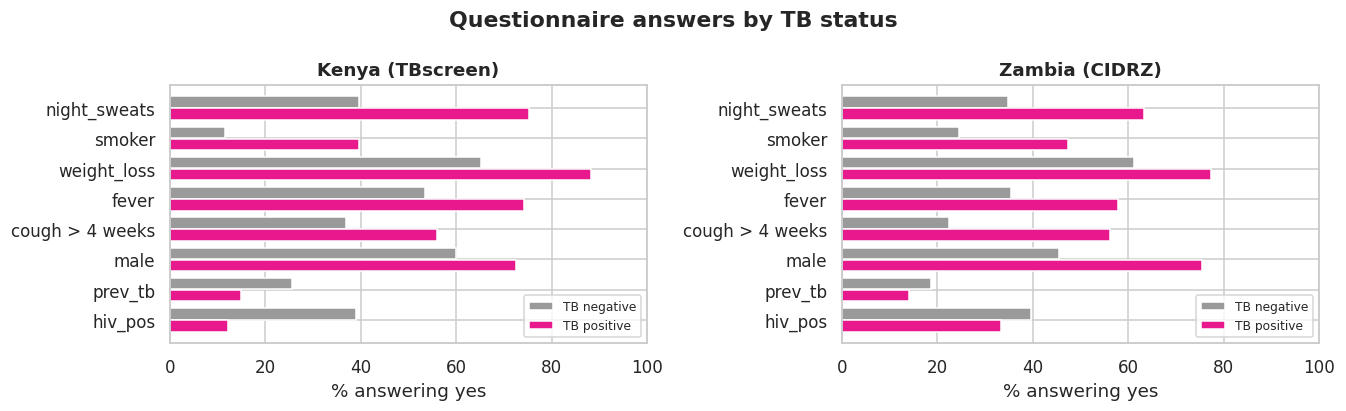

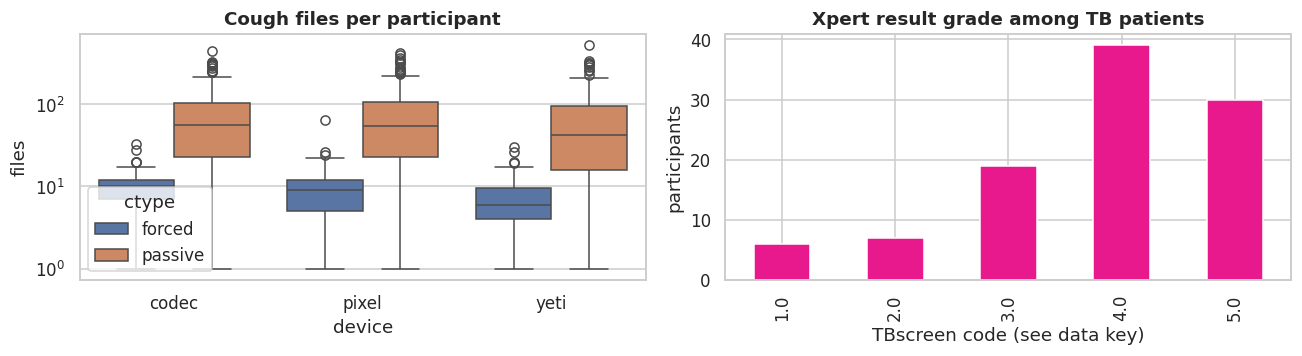

Age by TB status (median): {0: 39.5, 1: 36.0}


In [4]:
def find_input(marker, zip_hint, name, roots):
    # Return a folder containing `marker`, extracting a matching zip into WORK/restored/<name> if needed.
    for root in roots:
        root = Path(root)
        if not root.exists():
            continue
        hits = sorted(p for p in root.rglob(marker) if "restored" not in p.parts)
        if hits:
            return hits[0].parent
        for zp in sorted(root.rglob(f"*{zip_hint}*.zip")):
            with zipfile.ZipFile(zp) as z:
                if any(n == marker or n.endswith("/" + marker) for n in z.namelist()):
                    dest = WORK / "restored" / name
                    if not any(dest.rglob(marker)):
                        print(f"Extracting {zp.name} ...")
                        z.extractall(dest)
                    return next(dest.rglob(marker)).parent
    return None

Z_ROOTS = [CFG["ZAMBIA_INPUT"]] if CFG["ZAMBIA_INPUT"] else ["/kaggle/input"]
z_meta_dir = find_input("clinical_harmonised.csv", "metadata", "zambia_metadata", Z_ROOTS)
z_clin = pd.read_csv(z_meta_dir / "clinical_harmonised.csv").set_index("subject_id") if z_meta_dir else None
z_feat_dir = find_input("clean_index.csv", "features", "zambia_features", Z_ROOTS)
z_index = pd.read_csv(z_feat_dir / "clean_index.csv") if z_feat_dir else None
if z_index is not None:
    z_cohort = sorted(z_index.subject_id.unique())
    z_clin_c = z_clin.loc[z_clin.index.intersection(z_cohort)]
    print(f"Zambia: {len(z_cohort)} cohort participants, {len(z_index):,} clips")
else:
    z_clin_c = None
    print("Zambia bundles not found: Kenya-only analyses will run, Step 10 will be skipped.")

k_part = tb_clin.loc[tb_clin.index.intersection(coughs.subject_id.unique())]
# (a) the two populations side by side
def describe(clin, name, design, devices, ctypes, clip):
    return {"dataset": name, "design": design, "participants": len(clin), "TB positive": int(clin.label.sum()),
            "TB rate": f"{clin.label.mean():.0%}", "devices": devices, "cough types": ctypes, "clip format": clip}
rows = [describe(k_part, "Kenya (TBscreen)", "case-control: TB vs other respiratory illness", "codec mic, Pixel phone, Yeti mic",
                 "passive (natural) and forced", "1 s clips, zero-padded or split")]
if z_clin_c is not None:
    rows.append(describe(z_clin_c, "Zambia (CIDRZ)", "triage: symptomatic, contacts, new HIV", "3 phones (+ recorder)",
                         "solicited (3 singles + burst)", "single coughs, energy-trimmed"))
display(pd.DataFrame(rows).set_index("dataset").T)

# (b) clinical answers by TB status, Kenya beside Zambia
BIN = ["male", "smoker", "hiv_pos", "prev_tb", "fever", "weight_loss", "night_sweats"]
def yes_rates(clin):
    r = clin.groupby("label")[BIN].mean().T * 100
    r.loc["cough > 4 weeks"] = clin.assign(c=clin.cough_days > 28).groupby("label").c.mean() * 100
    return r.rename(columns={0: "TB negative", 1: "TB positive"})
sets = [("Kenya (TBscreen)", k_part)] + ([("Zambia (CIDRZ)", z_clin_c)] if z_clin_c is not None else [])
fig, axes = plt.subplots(1, len(sets), figsize=(6.2 * len(sets), 3.8), sharex=True, squeeze=False)
order = None
for ax, (name, clin) in zip(axes[0], sets):
    r = yes_rates(clin)
    order = order or list((r["TB positive"] - r["TB negative"]).sort_values().index)
    r = r.loc[order]
    y = np.arange(len(r))
    ax.barh(y + 0.2, r["TB negative"], 0.38, color="#9a9a9a", label="TB negative")
    ax.barh(y - 0.2, r["TB positive"], 0.38, color="#e8198c", label="TB positive")
    ax.set_yticks(y); ax.set_yticklabels(r.index); ax.set(title=name, xlabel="% answering yes", xlim=(0, 100))
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Questionnaire answers by TB status", fontweight="bold")
plt.tight_layout(); plt.show()

# (c) coughs per participant, by device and cough type
cpp = coughs.groupby(["ctype", "device", "subject_id"]).size().rename("n").reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
sns.boxplot(data=cpp, x="device", y="n", hue="ctype", ax=axes[0])
axes[0].set(title="Cough files per participant", ylabel="files", yscale="log")
if "lab_sptm_xprt_rslt_a" in k_part.columns:
    k_part[k_part.label == 1].lab_sptm_xprt_rslt_a.value_counts().sort_index().plot.bar(ax=axes[1], color="#e8198c")
    axes[1].set(title="Xpert result grade among TB patients", xlabel="TBscreen code (see data key)", ylabel="participants")
plt.tight_layout(); plt.show()
print("Age by TB status (median):", k_part.groupby("label").age.median().to_dict())

## Step 4. Did the three devices record the same coughs?

**Why it matters.** In Zambia every cough exists on three phones, which let us ask how much changing *only* the device alters a cough. TBscreen recorded with a phone (Pixel), a boundary microphone (codec) and a studio condenser microphone (Yeti). If the same cough key appears on several devices, the same paired analysis is possible here.

**What we expect.** Annotators discarded noisy recordings device by device, so not every cough survives on all three. The analysis in Step 8 uses the coughs present on two or three devices.

,on 1 device,on 2 devices,on 3 devices
ctype,,,
forced,405,272,87
passive,11956,5641,3235


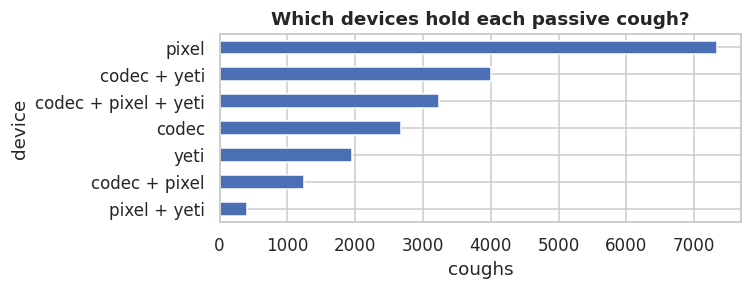

Coughs available on at least two devices: 9,235


In [5]:
per_key = coughs.groupby(["ctype", "key"]).device.nunique()
pairing = per_key.groupby(level=0).value_counts().unstack(fill_value=0)
pairing.columns = [f"on {c} device{'s' if c > 1 else ''}" for c in pairing.columns]
display(pairing)
combo = coughs[coughs.ctype == "passive"].groupby("key").device.apply(lambda s: " + ".join(sorted(set(s)))).value_counts()
ax = combo.sort_values().plot.barh(figsize=(7, 2.8), color="#4a6fb5")
ax.set(title="Which devices hold each passive cough?", xlabel="coughs")
plt.tight_layout(); plt.show()
PAIRED_KEYS = set(per_key[per_key >= 2].index.get_level_values(1))
print(f"Coughs available on at least two devices: {len(PAIRED_KEYS):,}")

## Step 5. Get the cough spectrograms without downloading 795 GB

**What we do.**
1. Choose the coughs. By default these are the paper's **T1** set (90 participants, 45 TB and 45 non-TB, with their published five folds) plus all forced coughs.
2. List the spectrogram folder once, to match each cough to its stored file (`<name>.wav.npy`).
3. Download those files in parallel and cache them, so later runs skip this step.
4. **Verify** them: for a sample of coughs with shared audio, recompute the spectrogram from the raw sound with the identical VGGish front end and compare. This tells us whether stored and recomputed features agree, which matters when Kenya is compared with Zambia, whose features we compute ourselves.

**Using less data.** `SAMPLE_FRACTION` keeps every participant but only a seeded share of each person's coughs, for example 0.25 for a quick run. Participants are never dropped, because with 90 people every one counts. For the comparison with the paper in Step 7b, run with 1.0 at least once.

**Front end.** The VGGish input is a 0.96 s, 64-band log-mel spectrogram (125 to 7500 Hz) at 16 kHz. The code below is an exact port of Google's AudioSet implementation that TBscreen used; it matches the original to within float rounding.

In [6]:
# VGGish input front end, ported from Google's AudioSet mel_features.py / vggish_input.py
# (Apache License 2.0), exactly as used to produce TBscreen's stored features.
import numpy as np
import librosa

VGG_SR, VGG_WIN_S, VGG_HOP_S = 16000, 0.025, 0.010
VGG_MELS, VGG_FMIN, VGG_FMAX, VGG_LOG_OFFSET = 64, 125.0, 7500.0, 0.01
VGG_FRAMES = 96


def _frame(data, window_length, hop_length):
    n = 1 + int(np.floor((data.shape[0] - window_length) / hop_length))
    if n < 1:
        raise ValueError(f"signal too short: {data.shape[0]} samples < window {window_length}")
    shape = (n, window_length) + data.shape[1:]
    strides = (data.strides[0] * hop_length,) + data.strides
    return np.lib.stride_tricks.as_strided(data, shape=shape, strides=strides)


def _periodic_hann(n):
    return 0.5 - 0.5 * np.cos(2 * np.pi / n * np.arange(n))


def _hz_to_mel(f):
    return 1127.0 * np.log(1.0 + f / 700.0)


def _mel_matrix(num_mel_bins, num_spectrogram_bins, sr, lo, hi):
    nyq = sr / 2.0
    bins_mel = _hz_to_mel(np.linspace(0.0, nyq, num_spectrogram_bins))
    edges = np.linspace(_hz_to_mel(lo), _hz_to_mel(hi), num_mel_bins + 2)
    m = np.empty((num_spectrogram_bins, num_mel_bins))
    for i in range(num_mel_bins):
        l, c, u = edges[i:i + 3]
        m[:, i] = np.maximum(0.0, np.minimum((bins_mel - l) / (c - l), (u - bins_mel) / (u - c)))
    m[0, :] = 0.0
    return m


def log_mel(data, sr=VGG_SR):
    win = int(round(sr * VGG_WIN_S)); hop = int(round(sr * VGG_HOP_S))
    fft = 2 ** int(np.ceil(np.log(win) / np.log(2.0)))
    frames = _frame(np.ascontiguousarray(data, dtype=np.float64), win, hop)
    spec = np.abs(np.fft.rfft(frames * _periodic_hann(win), fft))
    mel = spec @ _mel_matrix(VGG_MELS, spec.shape[1], sr, VGG_FMIN, VGG_FMAX)
    return np.log(mel + VGG_LOG_OFFSET)


def vggish_examples(wave, sr):
    """Waveform -> array (n_examples, 96, 64), as vggish_input.waveform_to_examples."""
    wave = np.asarray(wave, dtype=np.float64)
    if wave.ndim > 1:
        wave = wave.mean(axis=1)
    if sr != VGG_SR:
        wave = librosa.resample(wave, orig_sr=sr, target_sr=VGG_SR)
    lm = log_mel(wave, VGG_SR)
    return np.ascontiguousarray(_frame(lm, VGG_FRAMES, VGG_FRAMES), dtype=np.float32)


def vggish_example_padded(wave, sr, seconds=1.0):
    """Centre a short clip in `seconds` of zeros (as TBscreen did) and return one (96, 64) example."""
    wave = np.asarray(wave, dtype=np.float64)
    if wave.ndim > 1:
        wave = wave.mean(axis=1)
    if sr != VGG_SR:
        wave = librosa.resample(wave, orig_sr=sr, target_sr=VGG_SR)
    n = int(round(VGG_SR * seconds))
    wave = librosa.util.pad_center(wave[:n], size=n, mode="constant") if len(wave) < n else wave[:n]
    return vggish_examples(wave, VGG_SR)[0]


FOLD_ROOTS = [CFG["FOLDS_DIR"]] if CFG["FOLDS_DIR"] else ["/kaggle/input"]

def find_t1_folds(roots):
    # The published folds are folds/T1_0.csv ... T1_4.csv. TBscreen's code also holds RESULT files with the
    # same names (e.g. result_scalogram/10-4k/T1_0.csv), so only files inside a folder named "folds" count.
    is_fold = lambda parts: len(parts) >= 2 and parts[-2] == "folds" and re.fullmatch(r"T1_[0-9]\.csv", parts[-1])
    for root in map(Path, roots):
        if root.exists():
            hits = sorted(p for p in root.rglob("T1_*.csv") if is_fold(p.parts) and "restored" not in p.parts)
            if hits:
                return hits
    for root in map(Path, roots):                       # the code may be attached as an unextracted zip
        for zp in (sorted(root.rglob("*.zip")) if root.exists() else []):
            try:
                with zipfile.ZipFile(zp) as z:
                    names = [n for n in z.namelist() if is_fold(n.split("/"))]
                    if names:
                        dest = WORK / "restored" / "tbscreen_folds"; dest.mkdir(parents=True, exist_ok=True)
                        for n in names:
                            (dest / Path(n).name).write_bytes(z.read(n))
                        print(f"Extracted the published folds from {zp.name}")
                        return sorted(dest.glob("T1_[0-9].csv"))
            except zipfile.BadZipFile:
                continue
    return []

fold_files = find_t1_folds(FOLD_ROOTS)
if fold_files:
    t1 = pd.concat([pd.read_csv(f).assign(fold=int(f.stem.split("_")[1])) for f in fold_files], ignore_index=True)
    T1_FOLD = t1.drop_duplicates("subject").set_index("subject").fold
    T1_PATHS = set(t1.path.astype(str).str.replace(r".*[\\/]", "", regex=True).str.replace(r"\.wav$", "", regex=True))
    print(f"Published T1 folds: {len(T1_FOLD)} participants, {len(T1_PATHS):,} cough files, from {fold_files[0].parent}")
else:
    T1_FOLD, T1_PATHS = None, None
    print("T1 fold files not found: using our own stratified folds over all participants.\n"
          "  To use the paper's folds, attach the TBscreen code (it contains Figures/datacsv/folds/T1_0.csv ... T1_4.csv).")

sel = coughs.copy()
if CFG["PASSIVE_SCOPE"] == "T1" and T1_PATHS is not None:
    sel = sel[(sel.ctype != "passive") | sel.path.isin(T1_PATHS)]
    print(f"T1 cough files present in the passive table: {(sel.ctype == 'passive').sum():,} of {len(T1_PATHS):,}")
if CFG["SAMPLE_FRACTION"] < 1.0:
    # Keep every participant; for each participant and cough type keep a seeded share of their coughs.
    # Whole coughs are kept or dropped, so a cough kept on one device is kept on all devices.
    def keep_keys(g):
        keys = np.array(sorted(g.key.unique()))
        n = max(1, int(round(len(keys) * CFG["SAMPLE_FRACTION"])))
        r = np.random.default_rng(CFG["SEED"] + sum(map(ord, g.name[1])))
        return set(r.choice(keys, n, replace=False))
    chosen = set().union(*sel.groupby(["ctype", "subject_id"]).apply(keep_keys))
    before = len(sel)
    sel = sel[sel.key.isin(chosen)]
    print(f"Sampled {CFG['SAMPLE_FRACTION']:.0%} of each participant's coughs (seed {CFG['SEED']}): "
          f"{len(sel):,} of {before:,} files, {sel.subject_id.nunique()} participants kept")
if CFG["MAX_PER_PARTICIPANT_DEVICE"]:
    sel = sel.groupby(["ctype", "subject_id", "device"], group_keys=False).apply(
        lambda g: g.sample(min(len(g), CFG["MAX_PER_PARTICIPANT_DEVICE"]), random_state=CFG["SEED"]))
if CFG["FEATURE_SOURCE"] == "audio":
    sel = sel[sel.has_audio]
sel = sel.reset_index(drop=True)

def stem_of(name):
    return re.sub(r"(\.wav)?\.npy$", "", Path(name).name)

def resolve_names(df):
    names = pd.Series(index=df.index, dtype=object)
    for kind, g in df.groupby("ctype"):
        if CFG["FEATURE_SOURCE"] == "audio":
            names.loc[g.index] = LAYOUT[f"{kind}_audio"] + g.path + ".wav"
            continue
        t0 = time.time()
        listing = {stem_of(n): n for n, _ in STORE.list(LAYOUT[f"{kind}_vggish"])}
        print(f"  listed {len(listing):,} stored spectrograms for {kind} coughs in {time.time() - t0:.0f} s")
        names.loc[g.index] = g.path.map(listing)
    return names

def to_example(a):
    a = np.asarray(a, dtype=np.float32)
    if a.size and a.size % (96 * 64) == 0:
        return a.reshape(-1, 96, 64)[0]
    raise ValueError(f"unexpected stored shape {a.shape}")

def decode_npy(b):
    return to_example(np.load(io.BytesIO(b), allow_pickle=False))

def decode_wav(b):
    w, sr = sf.read(io.BytesIO(b), dtype="float32")
    return vggish_example_padded(w, sr)

sig = f"{CFG['PASSIVE_SCOPE']}_{CFG['FEATURE_SOURCE']}_{CFG['SAMPLE_FRACTION']}_{CFG['SEED']}_{CFG['MAX_PER_PARTICIPANT_DEVICE']}_{len(sel)}"
x_file, i_file = CACHE / f"tb_inputs_{sig}.npy", CACHE / f"tb_index_{sig}.csv"
if x_file.exists() and i_file.exists():
    X_IN, feat = np.load(x_file), pd.read_csv(i_file)
    print(f"Loaded {len(feat):,} cached spectrograms")
else:
    sel["blob"] = resolve_names(sel)
    no_file = sel.blob.isna()
    if no_file.any():
        print(f"  {no_file.sum():,} coughs have no stored file and are skipped, e.g. {sel[no_file].path.head(3).tolist()}")
    sel = sel[~no_file].reset_index(drop=True)
    got = fetch_many(sel.blob.tolist(), decode_wav if CFG["FEATURE_SOURCE"] == "audio" else decode_npy, label="spectrograms")
    ok = sel.blob.map(lambda n: got.get(n) is not None)
    feat = sel[ok].reset_index(drop=True)
    X_IN = np.stack([got[n] for n in feat.blob]).astype(np.float32)
    np.save(x_file, X_IN); feat.to_csv(i_file, index=False)
print(f"Spectrograms: {X_IN.shape} | " + ", ".join(f"{k}: {v:,}" for k, v in feat.ctype.value_counts().items()))
display(feat.groupby(["ctype", "device"]).agg(files=("path", "size"), participants=("subject_id", "nunique")))

T1 fold files not found: using our own stratified folds over all participants.
  To use the paper's folds, attach the TBscreen code (it contains Figures/datacsv/folds/T1_0.csv ... T1_4.csv).
  listed 1,225 stored spectrograms for forced coughs in 2 s
  listed 33,641 stored spectrograms for passive coughs in 41 s
  spectrograms: 3,415/34,153 in 29 s
  spectrograms: 6,830/34,153 in 56 s
  spectrograms: 10,245/34,153 in 83 s
  spectrograms: 13,660/34,153 in 110 s
  spectrograms: 17,075/34,153 in 137 s
  spectrograms: 20,490/34,153 in 164 s
  spectrograms: 23,905/34,153 in 191 s
  spectrograms: 27,320/34,153 in 218 s
  spectrograms: 30,735/34,153 in 245 s
  spectrograms: 34,150/34,153 in 272 s
  spectrograms: 34,153/34,153 in 272 s
Spectrograms: (34153, 96, 64) | passive: 32,943, forced: 1,210


files  participants
ctype   device                     
forced  codec     438            41
        pixel     490            46
        yeti      282            35
passive codec   11142           139
        pixel   12209           144
        yeti     9592           129

  audio files: 4/40 in 15 s
  audio files: 8/40 in 16 s
  audio files: 12/40 in 16 s
  audio files: 16/40 in 16 s
  audio files: 20/40 in 16 s
  audio files: 24/40 in 16 s
  audio files: 28/40 in 16 s
  audio files: 32/40 in 16 s
  audio files: 36/40 in 16 s
  audio files: 40/40 in 16 s
  3 audio files failed, e.g. [('v1/TBscreen_Dataset/Passive_coughs/Audio_files/PID_71C72_yeti.wav', "ResourceNotFoundError('The specified blob does not exist.\\nRequestId:05e5527e-001e-002d-2b88-6f0bbb000000\\nTime:2026-11-08T13:54:38.4821301Z\\nErrorCode:BlobNotFound')"), ('v1/TBscreen_Dataset/Passive_coughs/Audio_files/PID_68A_37_codec.wav', "ResourceNotFoundError('The specified blob does not exist.\\nRequestId:05e55347-001e-002d-5288-6f0bbb000000\\nTime:2026-11-08T13:54:39.9794408Z\\nErrorCode:BlobNotFound')")]
Checked 37 coughs: median correlation 0.9999, median largest difference 0.386 (log-mel units)
Verdict: the stored spectrograms match our front end.


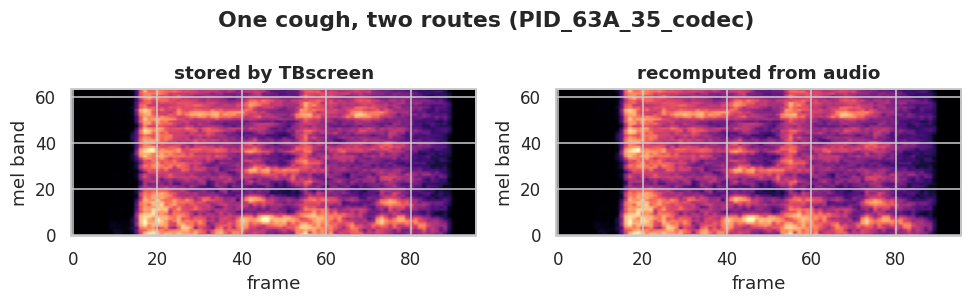

In [7]:
# Verify the stored spectrograms against the raw audio for a sample of coughs
AGREE = None
if CFG["FEATURE_SOURCE"] == "provided" and CFG["N_AUDIO_CHECK"] and feat.has_audio.any():
    sample = feat[feat.has_audio].sample(min(CFG["N_AUDIO_CHECK"], int(feat.has_audio.sum())), random_state=CFG["SEED"])
    wav_names = (sample.ctype.map(lambda k: LAYOUT[f"{k}_audio"]) + sample.path + ".wav").tolist()
    rec = fetch_many(wav_names, decode_wav, label="audio files")
    rows = []
    for (i, r), wn in zip(sample.iterrows(), wav_names):
        if rec.get(wn) is None:
            continue
        a, b = X_IN[i].ravel(), rec[wn].ravel()
        rows.append(dict(path=r.path, max_abs_diff=float(np.abs(a - b).max()), corr=float(np.corrcoef(a, b)[0, 1])))
    chk = pd.DataFrame(rows)
    if len(chk):
        AGREE = bool(chk["corr"].median() > 0.99)
        print(f"Checked {len(chk)} coughs: median correlation {chk['corr'].median():.4f}, "
              f"median largest difference {chk.max_abs_diff.median():.3g} (log-mel units)")
        print("Verdict:", "the stored spectrograms match our front end." if AGREE else
              "they DIFFER from our front end; for Kenya-Zambia comparisons set FEATURE_SOURCE='audio'.")
        i0, wn0 = sample.index[0], wav_names[0]
        if rec.get(wn0) is not None:
            fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
            for ax, img, t in zip(axes, (X_IN[i0], rec[wn0]), ("stored by TBscreen", "recomputed from audio")):
                ax.imshow(img.T, origin="lower", aspect="auto", cmap="magma"); ax.set(title=t, xlabel="frame", ylabel="mel band")
            fig.suptitle(f"One cough, two routes ({sample.path.iloc[0]})", fontweight="bold")
            plt.tight_layout(); plt.show()

## Step 6. From spectrograms to embeddings

**What we do.** Pass every spectrogram through the **pretrained** VGGish network (no TB training) to get 128 numbers per cough, exactly as in our Zambia embedding analysis. We also keep a simple **spectrogram summary** (the mean and spread of each of the 64 mel bands) as a second, training-free representation. Embeddings are cached.

In [8]:
def spectral_summary(X):
    return np.concatenate([X.mean(axis=1), X.std(axis=1)], axis=1).astype(np.float32)

VGGISH_URL = "https://github.com/harritaylor/torchvggish/releases/download/v0.1/vggish-10086976.pth"
if TORCH_OK:
    class VGGishBackbone(nn.Module):
        def __init__(self):
            super().__init__()
            def conv(cin, cout):
                return [nn.Conv2d(cin, cout, 3, 1, 1), nn.ReLU(inplace=True)]
            self.features = nn.Sequential(*conv(1, 64), nn.MaxPool2d(2, 2), *conv(64, 128), nn.MaxPool2d(2, 2),
                                          *conv(128, 256), *conv(256, 256), nn.MaxPool2d(2, 2),
                                          *conv(256, 512), *conv(512, 512), nn.MaxPool2d(2, 2))
            self.embeddings = nn.Sequential(nn.Linear(512 * 24, 4096), nn.ReLU(True), nn.Linear(4096, 4096), nn.ReLU(True),
                                            nn.Linear(4096, 128), nn.ReLU(True))
        def forward(self, x):                       # x: (N, 1, 96, 64)
            x = self.features(x).permute(0, 2, 3, 1).contiguous()
            return self.embeddings(x.view(x.size(0), -1))

    def vggish_weights():
        wpath = WORK / "vggish-10086976.pth"
        if not wpath.exists():
            torch.hub.download_url_to_file(VGGISH_URL, str(wpath), hash_prefix="10086976")
        try:
            return torch.load(wpath, map_location="cpu", weights_only=True)
        except TypeError:
            return torch.load(wpath, map_location="cpu")

    def vggish_embed(X, batch=256):
        bb = VGGishBackbone(); bb.load_state_dict(vggish_weights(), strict=True); bb.eval().to(DEVICE)
        out = []
        with torch.no_grad():
            for i in range(0, len(X), batch):
                out.append(bb(torch.as_tensor(X[i:i + batch], device=DEVICE)[:, None]).cpu().numpy())
        return np.concatenate(out).astype(np.float32)

def embed_cached(X, tag):
    f = CACHE / f"emb_{tag}.npy"
    if f.exists():
        return np.load(f)
    t0 = time.time(); E = vggish_embed(X); np.save(f, E)
    print(f"  embedded {len(X):,} spectrograms ({tag}) in {time.time() - t0:.0f} s on {DEVICE}")
    return E

FEATS = {"Spectrogram summary": spectral_summary(X_IN)}
if TORCH_OK:
    FEATS["VGGish (pretrained)"] = embed_cached(X_IN, f"tb_{sig}")
PRIMARY = "VGGish (pretrained)" if TORCH_OK else "Spectrogram summary"
if not TORCH_OK:
    print("PyTorch is not available: VGGish embeddings are skipped and the spectrogram summary stands in.")
print("Representations:", {k: v.shape for k, v in FEATS.items()}, "| primary:", PRIMARY)

100%|██████████| 275M/275M [00:05<00:00, 51.3MB/s]


  embedded 34,153 spectrograms (tb_T1_provided_1.0_42_None_34153) in 23 s on cuda
Representations: {'Spectrogram summary': (34153, 128), 'VGGish (pretrained)': (34153, 128)} | primary: VGGish (pretrained)


## Step 7. Baselines on the paper's own folds

**Setting.** Passive coughs of the T1 participants, split into TBscreen's **published five folds**, so every person is tested exactly once by models that never saw them.

**Three models, as in our study design.**
* **Model B, questionnaire only:** logistic regression on the clinical variables kept in Step 2.
* **Audio only:** a linear classifier on each cough's embedding; a participant's score is the mean over their coughs, as in TBscreen.
* **Model A, questionnaire + audio:** logistic regression on the clinical variables plus the participant's audio score. The audio score used for training comes from inner folds, so it is always a prediction for people the audio model did not see.

**Reported.** AUROC per participant (pooled over folds, with a bootstrap interval and the mean ± s.d. across folds), the paired gain $\Delta$ = AUROC(A) − AUROC(B) with DeLong's test, specificity at 90% sensitivity, and per-cough AUROC so the audio model can be set beside the published values.

Baseline set: 148 participants (TB 102), 32,943 passive coughs, folds [0, 1, 2, 3, 4]


,setting,model,AUROC,95% CI,per fold mean ± sd,spec. at 90% sens.
0,"Kenya T1, Spectrogram summary",Questionnaire only (B),0.714,0.63 to 0.80,0.713 ± 0.080,0.26
1,"Kenya T1, Spectrogram summary",Audio only,0.638,0.54 to 0.74,0.647 ± 0.131,0.11
2,"Kenya T1, Spectrogram summary",Questionnaire + audio (A),0.686,0.60 to 0.78,0.679 ± 0.071,0.2
3,"Kenya T1, Spectrogram summary",Gain Δ = A − B,-0.029,-0.05 to -0.01,p = 0.01,
4,"Kenya T1, Spectrogram summary","Audio only, per cough",0.589,,,
5,"Kenya T1, VGGish (pretrained)",Questionnaire only (B),0.714,0.63 to 0.80,0.713 ± 0.080,0.26
6,"Kenya T1, VGGish (pretrained)",Audio only,0.711,0.61 to 0.80,0.719 ± 0.130,0.41
7,"Kenya T1, VGGish (pretrained)",Questionnaire + audio (A),0.709,0.62 to 0.80,0.689 ± 0.083,0.26
8,"Kenya T1, VGGish (pretrained)",Gain Δ = A − B,-0.006,-0.04 to 0.03,p = 0.76,
9,"Kenya T1, VGGish (pretrained)","Audio only, per cough",0.618,,,


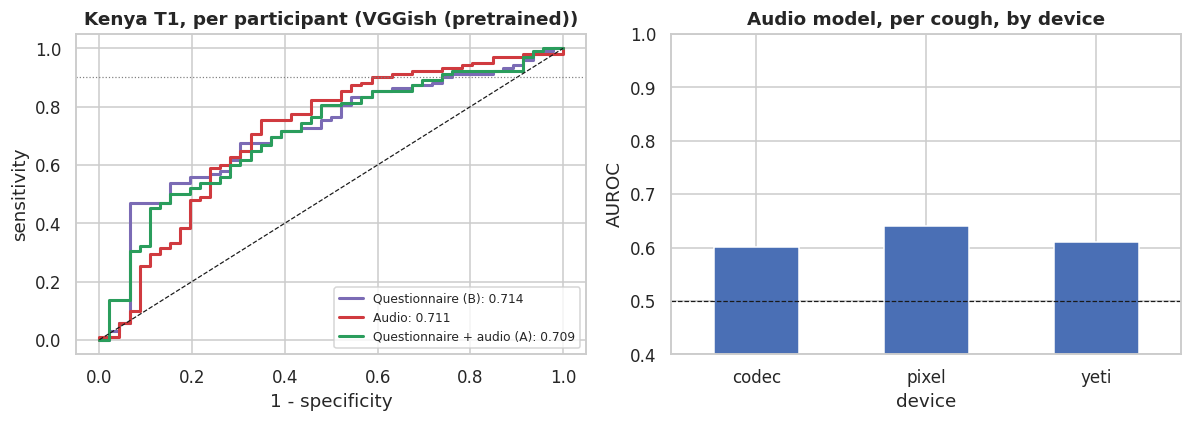

In [9]:
def logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))

def lr_pipe(C, balanced=True, impute=False):
    steps = ([SimpleImputer(strategy="median")] if impute else []) + [StandardScaler(),
             LogisticRegression(C=C, max_iter=5000, class_weight="balanced" if balanced else None)]
    return make_pipeline(*steps)

def probe(Xtr, ytr, Xte):
    return lr_pipe(CFG["PROBE_C"]).fit(Xtr, ytr).predict_proba(Xte)[:, 1]

def part_mean(subjects, p):
    return pd.Series(np.asarray(p, dtype=float)).groupby(np.asarray(subjects)).mean()

def _midrank(x):
    J = np.argsort(x); Z = x[J]; N = len(x); T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1; i = j
    out = np.empty(N); out[J] = T
    return out

def delong(y, p_ref, p_new):
    # Paired DeLong test: difference AUROC(p_new) - AUROC(p_ref), with 95% CI and p-value.
    y = np.asarray(y).astype(int); pos = y == 1; m, n = pos.sum(), (~pos).sum()
    aucs, V10, V01 = [], [], []
    for p in (p_ref, p_new):
        p = np.asarray(p, dtype=float); X, Y = p[pos], p[~pos]
        tx, ty, tz = _midrank(X), _midrank(Y), _midrank(np.r_[X, Y])
        aucs.append((tz[:m].sum() - m * (m + 1) / 2) / (m * n))
        V10.append((tz[:m] - tx) / n); V01.append(1 - (tz[m:] - ty) / m)
    S = np.cov(np.vstack(V10)) / m + np.cov(np.vstack(V01)) / n
    se = np.sqrt(max(S[0, 0] + S[1, 1] - 2 * S[0, 1], 1e-12)); d = aucs[1] - aucs[0]
    return dict(diff=d, lo=d - 1.96 * se, hi=d + 1.96 * se, p=float(2 * norm.sf(abs(d / se))))

def boot_ci(y, p, n=None):
    y, p = np.asarray(y), np.asarray(p); r = np.random.default_rng(CFG["SEED"]); out = []
    for _ in range(n or CFG["N_BOOT"]):
        i = r.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            out.append(roc_auc_score(y[i], p[i]))
    return np.percentile(out, [2.5, 97.5])

def spec_at_sens(y, p, sens=0.9):
    fpr, tpr, _ = roc_curve(y, p)
    return float(1 - fpr[min(np.searchsorted(tpr, sens), len(fpr) - 1)])

def run_cv(P, clips, X, folds, inner_k=4):
    # Participant-level cross-validation of B, audio and A; returns participant and cough predictions.
    prow, crow = [], []
    for f in sorted(np.unique(folds)):
        te, tr = P.index[folds == f], P.index[folds != f]
        ctr, cte = clips.subject_id.isin(tr).values, clips.subject_id.isin(te).values
        p_cte = probe(X[ctr], clips.label.values[ctr], X[cte])
        crow.append(pd.DataFrame({"subject_id": clips.subject_id.values[cte], "label": clips.label.values[cte],
                                  "device": clips.device.values[cte], "p": p_cte, "fold": f}))
        a_te = part_mean(clips.subject_id.values[cte], p_cte).reindex(te)
        a_tr = pd.Series(np.nan, index=tr)
        k_in = min(inner_k, int(P.loc[tr, "label"].value_counts().min()))
        for itr, iva in StratifiedKFold(k_in, shuffle=True, random_state=CFG["SEED"]).split(tr, P.loc[tr, "label"]):
            m_tr, m_va = clips.subject_id.isin(tr[itr]).values, clips.subject_id.isin(tr[iva]).values
            a_tr.update(part_mean(clips.subject_id.values[m_va], probe(X[m_tr], clips.label.values[m_tr], X[m_va])))
        ytr = P.loc[tr, "label"].values
        b = lr_pipe(CFG["CLIN_C"], impute=True).fit(P.loc[tr, CLIN_USE], ytr).predict_proba(P.loc[te, CLIN_USE])[:, 1]
        Atr = np.c_[P.loc[tr, CLIN_USE].values, logit(a_tr.values)]
        Ate = np.c_[P.loc[te, CLIN_USE].values, logit(a_te.values)]
        a = lr_pipe(CFG["CLIN_C"], impute=True).fit(Atr, ytr).predict_proba(Ate)[:, 1]
        prow.append(pd.DataFrame({"label": P.loc[te, "label"].values, "fold": f, "B": b, "audio": a_te.values, "A": a}, index=te))
    return pd.concat(prow), pd.concat(crow, ignore_index=True)

def summarise(pp, name, cp=None):
    rows = []
    for m, lab in (("B", "Questionnaire only (B)"), ("audio", "Audio only"), ("A", "Questionnaire + audio (A)")):
        lo, hi = boot_ci(pp.label, pp[m])
        per = [roc_auc_score(g.label, g[m]) for _, g in pp.groupby("fold") if g.label.nunique() == 2]
        rows.append({"setting": name, "model": lab, "AUROC": round(roc_auc_score(pp.label, pp[m]), 3),
                     "95% CI": f"{lo:.2f} to {hi:.2f}", "per fold mean ± sd": f"{np.mean(per):.3f} ± {np.std(per):.3f}",
                     "spec. at 90% sens.": round(spec_at_sens(pp.label, pp[m]), 2)})
    d = delong(pp.label, pp.B, pp.A)
    rows.append({"setting": name, "model": "Gain Δ = A − B", "AUROC": round(d["diff"], 3),
                 "95% CI": f"{d['lo']:.2f} to {d['hi']:.2f}", "per fold mean ± sd": f"p = {d['p']:.2f}", "spec. at 90% sens.": ""})
    if cp is not None:
        rows.append({"setting": name, "model": "Audio only, per cough", "AUROC": round(roc_auc_score(cp.label, cp.p), 3),
                     "95% CI": "", "per fold mean ± sd": "", "spec. at 90% sens.": ""})
    return pd.DataFrame(rows)

# participants and clips for the passive-cough baseline
idx_p = feat.index[feat.ctype == "passive"].values
CP = feat.loc[idx_p].reset_index(drop=True)
KP = tb_clin.loc[sorted(CP.subject_id.unique())].copy()
KP["fold"] = KP.index.map(T1_FOLD) if (T1_FOLD is not None and CFG["PASSIVE_SCOPE"] == "T1") else np.nan
need = KP.fold.isna()
if need.any():
    sub = KP.index[need]
    for k, (_, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=CFG["SEED"]).split(sub, KP.loc[sub, "label"])):
        KP.loc[sub[te], "fold"] = k
KP["fold"] = KP.fold.astype(int)
print(f"Baseline set: {len(KP)} participants (TB {int(KP.label.sum())}), {len(CP):,} passive coughs, folds {sorted(map(int, KP.fold.unique()))}")

BASE, tables = {}, []
for name, F in FEATS.items():
    pp, cp = run_cv(KP, CP, F[idx_p], KP.fold.values)
    BASE[name] = (pp, cp)
    tables.append(summarise(pp, f"Kenya T1, {name}", cp))
base_table = pd.concat(tables, ignore_index=True)
display(base_table)
base_table.to_csv(OUT / "kenya_baselines.csv", index=False)

pp, cp = BASE[PRIMARY]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for m, col, lab in (("B", "#7b6bb5", "Questionnaire (B)"), ("audio", "#d03a3f", "Audio"), ("A", "#2a9d5c", "Questionnaire + audio (A)")):
    fpr, tpr, _ = roc_curve(pp.label, pp[m])
    axes[0].plot(fpr, tpr, color=col, lw=2, label=f"{lab}: {roc_auc_score(pp.label, pp[m]):.3f}")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[0].axhline(0.9, color="grey", ls=":", lw=0.8)
axes[0].set(title=f"Kenya T1, per participant ({PRIMARY})", xlabel="1 - specificity", ylabel="sensitivity"); axes[0].legend(fontsize=8)
per_dev = cp.groupby("device").apply(lambda g: roc_auc_score(g.label, g.p) if g.label.nunique() == 2 else np.nan)
per_dev.plot.bar(ax=axes[1], color="#4a6fb5", rot=0); axes[1].axhline(0.5, color="k", ls="--", lw=0.8)
axes[1].set(title="Audio model, per cough, by device", ylabel="AUROC", ylim=(0.4, 1.0))
plt.tight_layout(); plt.show()

### Step 7b. Reproducing the paper: fine-tuned VGGish

**What we do.** Fine-tune VGGish end to end on the T1 passive coughs, as TBscreen did: a 128 → 1 head, learning rates of 10⁻⁴ (head) and 10⁻⁵ (backbone), batch 32, step decay every 20 epochs. For each test fold the next fold is used for early stopping and the remaining three for training, and the best epoch is restored before testing.

**Target.** The published result files give **0.661 ± 0.063 per cough** and **0.744 ± 0.138 per participant**. Landing near these numbers confirms that our pipeline reads the data correctly. This step needs a GPU; without PyTorch it is skipped.

In [10]:
PUBLISHED = {"VGGish fine-tuned (TBscreen)": (0.661, 0.063, 0.744, 0.138),
             "Mel-spectrogram ResNet18 (TBscreen)": (0.671, 0.100, 0.768, 0.065),
             "Scalogram ResNet18, main model (TBscreen)": (0.793, 0.057, 0.902, 0.046)}
ft_rows = []
if TORCH_OK and CFG["RUN_FINETUNE"]:
    Xp, yp, sp = X_IN[idx_p], CP.label.values.astype(np.float32), CP.subject_id.values
    fp = CP.subject_id.map(KP.fold).values
    W0 = vggish_weights()
    def make_model():
        bb = VGGishBackbone(); bb.load_state_dict(W0, strict=True)
        return nn.Sequential(bb, nn.Linear(128, 1)).to(DEVICE)
    def predict(model, X, batch=256):
        model.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(X), batch):
                out.append(torch.sigmoid(model(torch.as_tensor(X[i:i + batch], device=DEVICE)[:, None])).squeeze(1).cpu().numpy())
        return np.concatenate(out)
    for k in CFG["FT_FOLDS"]:
        v = (k + 1) % 5
        tr, va, te = (fp != k) & (fp != v), fp == v, fp == k
        torch.manual_seed(CFG["SEED"] + k)
        model = make_model()
        opt = torch.optim.Adam([{"params": model[0].parameters(), "lr": CFG["FT_LR_BACKBONE"]},
                                {"params": model[1].parameters(), "lr": CFG["FT_LR_HEAD"]}])
        sched = torch.optim.lr_scheduler.StepLR(opt, step_size=20, gamma=0.1)
        lossf = nn.BCEWithLogitsLoss()
        best, best_state, wait, t0 = -1.0, None, 0, time.time()
        idx_tr = np.where(tr)[0]
        for ep in range(CFG["FT_EPOCHS"]):
            model.train(); perm = np.random.default_rng(CFG["SEED"] + ep).permutation(idx_tr)
            for i in range(0, len(perm), CFG["FT_BATCH"]):
                b = perm[i:i + CFG["FT_BATCH"]]
                xb = torch.as_tensor(Xp[b], device=DEVICE)[:, None]; yb = torch.as_tensor(yp[b], device=DEVICE)[:, None]
                opt.zero_grad(); loss = lossf(model(xb), yb); loss.backward(); opt.step()
            sched.step()
            auc_v = roc_auc_score(yp[va], predict(model, Xp[va]))
            if auc_v > best:
                best, best_state, wait = auc_v, copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
            if ep + 1 >= CFG["FT_MIN_EPOCHS"] and wait >= CFG["FT_PATIENCE"]:
                break
        model.load_state_dict(best_state)
        p_te = predict(model, Xp[te])
        pm = part_mean(sp[te], p_te); yl = KP.label.reindex(pm.index)
        ft_rows.append(dict(fold=k, epochs=ep + 1, val_auroc=round(best, 3), cough_auroc=round(roc_auc_score(yp[te], p_te), 3),
                            participant_auroc=round(roc_auc_score(yl, pm), 3), minutes=round((time.time() - t0) / 60, 1)))
        print(ft_rows[-1], flush=True)
        del model, opt
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
    ft = pd.DataFrame(ft_rows); ft.to_csv(OUT / "kenya_vggish_finetune_folds.csv", index=False); display(ft)
else:
    print("Fine-tuning skipped (needs PyTorch, and RUN_FINETUNE must be True).")

comp = [{"model": k, "per cough": f"{a:.3f} ± {b:.3f}", "per participant": f"{c:.3f} ± {d:.3f}", "source": "published"}
        for k, (a, b, c, d) in PUBLISHED.items()]
if ft_rows:
    comp.append({"model": "VGGish fine-tuned (ours)", "per cough": f"{ft.cough_auroc.mean():.3f} ± {ft.cough_auroc.std(ddof=0):.3f}",
                 "per participant": f"{ft.participant_auroc.mean():.3f} ± {ft.participant_auroc.std(ddof=0):.3f}", "source": "this run"})
for name, (pp_, cp_) in BASE.items():
    pc = [roc_auc_score(g.label, g.p) for _, g in cp_.groupby("fold") if g.label.nunique() == 2]
    pa = [roc_auc_score(g.label, g.audio) for _, g in pp_.groupby("fold") if g.label.nunique() == 2]
    comp.append({"model": f"{name} + linear probe (ours)", "per cough": f"{np.mean(pc):.3f} ± {np.std(pc):.3f}",
                 "per participant": f"{np.mean(pa):.3f} ± {np.std(pa):.3f}", "source": "this run"})
comp = pd.DataFrame(comp); display(comp); comp.to_csv(OUT / "kenya_reproduction.csv", index=False)

{'fold': 0, 'epochs': 7, 'val_auroc': np.float64(0.705), 'cough_auroc': np.float64(0.52), 'participant_auroc': np.float64(0.556), 'minutes': 4.0}
{'fold': 1, 'epochs': 8, 'val_auroc': np.float64(0.679), 'cough_auroc': np.float64(0.753), 'participant_auroc': np.float64(0.873), 'minutes': 4.3}
{'fold': 2, 'epochs': 20, 'val_auroc': np.float64(0.584), 'cough_auroc': np.float64(0.711), 'participant_auroc': np.float64(0.75), 'minutes': 11.4}
{'fold': 3, 'epochs': 7, 'val_auroc': np.float64(0.761), 'cough_auroc': np.float64(0.538), 'participant_auroc': np.float64(0.494), 'minutes': 4.0}
{'fold': 4, 'epochs': 18, 'val_auroc': np.float64(0.656), 'cough_auroc': np.float64(0.767), 'participant_auroc': np.float64(0.839), 'minutes': 10.2}


,fold,epochs,val_auroc,cough_auroc,participant_auroc,minutes
0,0,7,0.705,0.520,0.556,4.0
1,1,8,0.679,0.753,0.873,4.3
2,2,20,0.584,0.711,0.750,11.4
3,3,7,0.761,0.538,0.494,4.0
4,4,18,0.656,0.767,0.839,10.2


,model,per cough,per participant,source
0,VGGish fine-tuned (TBscreen),0.661 ± 0.063,0.744 ± 0.138,published
1,Mel-spectrogram ResNet18 (TBscreen),0.671 ± 0.100,0.768 ± 0.065,published
2,"Scalogram ResNet18, main model (TBscreen)",0.793 ± 0.057,0.902 ± 0.046,published
3,VGGish fine-tuned (ours),0.658 ± 0.107,0.702 ± 0.152,this run
4,Spectrogram summary + linear probe (ours),0.592 ± 0.083,0.647 ± 0.131,this run
5,VGGish (pretrained) + linear probe (ours),0.621 ± 0.079,0.719 ± 0.130,this run


## Step 8. Is the feature space organised by device? (the Zambia analysis, repeated in Kenya)

**Four checks on the passive coughs, as in Zambia.**
1. **Probes.** Can a linear classifier, tested on unseen participants, recover the **device**? The **TB status**? Device AUROC far above TB AUROC means recording conditions dominate the features.
2. **Map.** A t-SNE map of the coughs, coloured by device and by TB status.
3. **Same cough, different device.** Using the cough keys from Step 4: is one cough recorded on two devices further apart than two *different* participants on one device?
4. **Unseen device.** Train the TB classifier with and without a device, test on that device, and measure the drop in AUROC and how far each participant's score moves.

**Kenya's devices differ more than Zambia's phones.** TBscreen used a phone, a boundary microphone and a studio microphone, so a stronger device signal than in Zambia would not be surprising.

,features,device: accuracy (chance 0.33),device: AUROC,TB: AUROC per cough,TB: AUROC per participant
0,Spectrogram summary,0.542,0.728,0.591,0.630
1,VGGish (pretrained),0.480,0.666,0.613,0.712


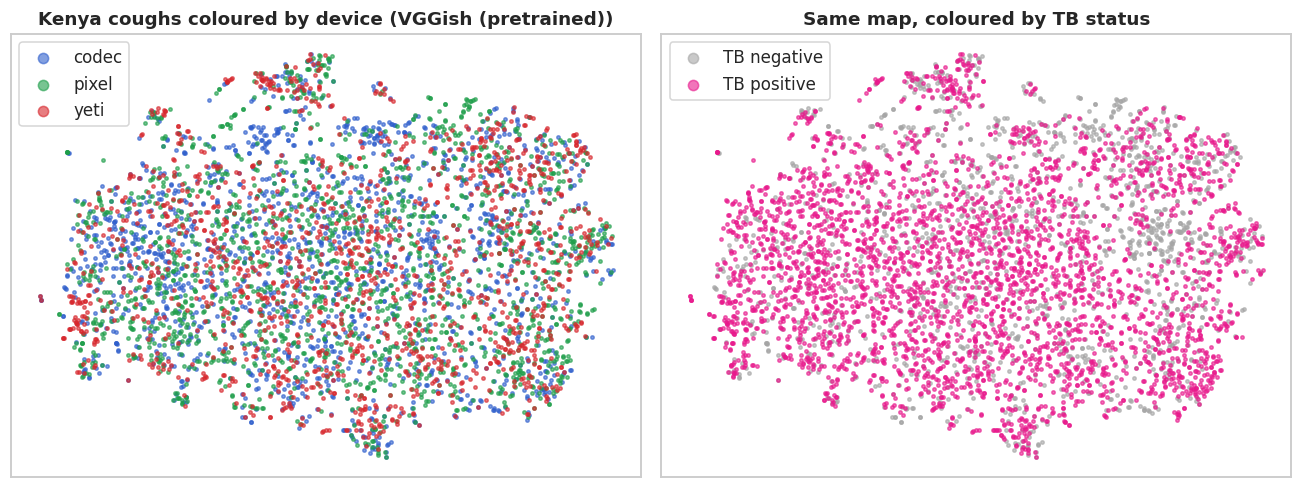

In [11]:
groups_p = CP.subject_id.values
cvg = StratifiedGroupKFold(5, shuffle=True, random_state=CFG["SEED"])
DEVS = sorted(CP.device.unique())
probe_rows = []
for name, F in FEATS.items():
    Xf = F[idx_p]
    dev_p = cross_val_predict(lr_pipe(CFG["PROBE_C"], balanced=False), Xf, CP.device, cv=cvg, groups=groups_p, method="predict_proba")
    tb_p = cross_val_predict(lr_pipe(CFG["PROBE_C"]), Xf, CP.label, cv=cvg, groups=groups_p, method="predict_proba")[:, 1]
    per = pd.DataFrame({"s": groups_p, "y": CP.label.values, "p": tb_p}).groupby("s").agg(y=("y", "first"), p=("p", "mean"))
    probe_rows.append({"features": name,
                       f"device: accuracy (chance {1 / len(DEVS):.2f})": round(balanced_accuracy_score(CP.device, np.array(DEVS)[dev_p.argmax(1)]), 3),
                       "device: AUROC": round(roc_auc_score(CP.device, dev_p, multi_class="ovr", labels=DEVS), 3),
                       "TB: AUROC per cough": round(roc_auc_score(CP.label, tb_p), 3),
                       "TB: AUROC per participant": round(roc_auc_score(per.y, per.p), 3)})
kenya_probe = pd.DataFrame(probe_rows); display(kenya_probe); kenya_probe.to_csv(OUT / "kenya_device_vs_tb_probe.csv", index=False)

# map
sub = rng.choice(len(CP), min(len(CP), 5000), replace=False)
Z2 = TSNE(2, perplexity=min(30, max(5, len(sub) // 4)), init="pca", random_state=CFG["SEED"]).fit_transform(
    StandardScaler().fit_transform(FEATS[PRIMARY][idx_p][sub]))
pal = dict(zip(DEVS, ["#2f5fcc", "#1e9e4a", "#d7262c", "#999999"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for d in DEVS:
    m = CP.device.values[sub] == d
    axes[0].scatter(Z2[m, 0], Z2[m, 1], s=5, alpha=0.6, color=pal[d], label=d)
axes[0].set(title=f"Kenya coughs coloured by device ({PRIMARY})", xticks=[], yticks=[]); axes[0].legend(markerscale=3)
for v, col, lab in ((0, "#a5a5a5", "TB negative"), (1, "#e8198c", "TB positive")):
    m = CP.label.values[sub] == v
    axes[1].scatter(Z2[m, 0], Z2[m, 1], s=5, alpha=0.6, color=col, label=lab)
axes[1].set(title="Same map, coloured by TB status", xticks=[], yticks=[]); axes[1].legend(markerscale=3)
plt.tight_layout(); plt.show()

,0,1
features,Spectrogram summary,VGGish (pretrained)
"same cough, different device: median",0.073,0.542
"same person & device, different cough: median",0.297,0.777
"different people, same device: median",1.0,1.026
"different people, different devices: median",1.003,1.027
same cough on two devices farther apart than a typical different-person pair (%),5.8,6.5
"same cough, codec vs pixel: median",0.055,0.551
"same cough, codec vs yeti: median",0.069,0.53
"same cough, pixel vs yeti: median",0.109,0.55


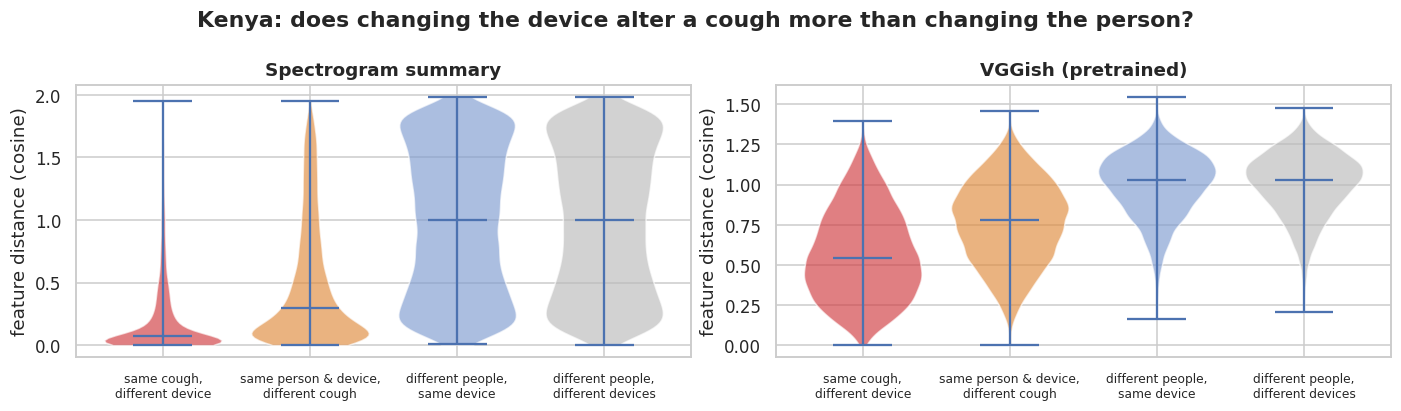

,features,held-out device,participants,"AUROC, device seen","AUROC, device unseen",score shift,change
0,Spectrogram summary,codec,139,0.598,0.618,0.054,0.020
1,Spectrogram summary,pixel,144,0.620,0.545,0.059,-0.075
2,Spectrogram summary,yeti,129,0.688,0.636,0.038,-0.052
3,VGGish (pretrained),codec,139,0.626,0.624,0.032,-0.002
4,VGGish (pretrained),pixel,144,0.707,0.637,0.050,-0.070
5,VGGish (pretrained),yeti,129,0.727,0.725,0.035,-0.002


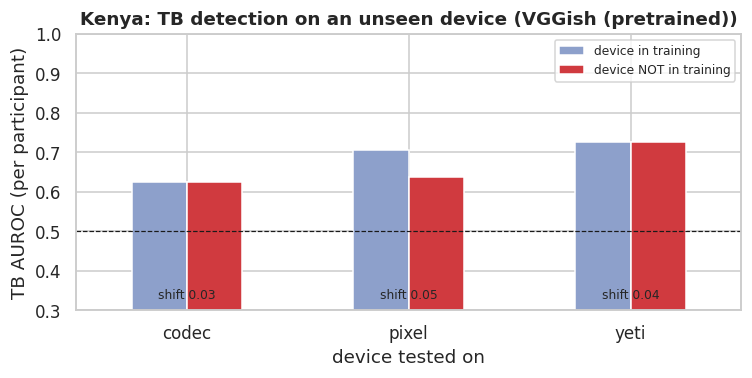

In [12]:
# Same cough on two devices, against other kinds of pairs
def cos_dist(Fz, a, b):
    A, B = Fz[a], Fz[b]
    return 1 - (A * B).sum(1) / (np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1) + 1e-12)

m = CP.reset_index(drop=True)
same_cough = np.array([(i, j) for _, g in m.groupby("key") for i, j in itertools.combinations(g.index, 2)
                       if m.device[i] != m.device[j]])
dist_rows, dist_sets = [], {}
if len(same_cough):
    n = len(same_cough)
    same_pd = [(i, j) for _, g in m.groupby(["subject_id", "device"])
               for i, j in itertools.combinations(g.index[:30], 2)]          # at most 30 coughs per participant and device
    same_pd = np.array(same_pd)[rng.choice(len(same_pd), min(n, len(same_pd)), replace=False)] if same_pd else np.empty((0, 2), int)
    a, b = rng.integers(0, len(m), 8 * n), rng.integers(0, len(m), 8 * n)
    diffp = m.subject_id.values[a] != m.subject_id.values[b]; samed = m.device.values[a] == m.device.values[b]
    pairs = {"same cough,\ndifferent device": same_cough, "same person & device,\ndifferent cough": same_pd,
             "different people,\nsame device": np.c_[a, b][diffp & samed][:n], "different people,\ndifferent devices": np.c_[a, b][diffp & ~samed][:n]}
    for name, F in FEATS.items():
        Fz = StandardScaler().fit_transform(F[idx_p])
        d = {k: cos_dist(Fz, v[:, 0], v[:, 1]) for k, v in pairs.items() if len(v)}
        dist_sets[name] = d
        ref = np.median(d["different people,\nsame device"])
        row = {"features": name, **{k.replace("\n", " ") + ": median": round(float(np.median(v)), 3) for k, v in d.items()},
               "same cough on two devices farther apart than a typical different-person pair (%)":
                   round(100 * float((d["same cough,\ndifferent device"] > ref).mean()), 1)}
        dv = m.device.values
        for d1, d2 in itertools.combinations(DEVS, 2):
            mk = ((dv[same_cough[:, 0]] == d1) & (dv[same_cough[:, 1]] == d2)) | ((dv[same_cough[:, 0]] == d2) & (dv[same_cough[:, 1]] == d1))
            if mk.any():
                row[f"same cough, {d1} vs {d2}: median"] = round(float(np.median(d["same cough,\ndifferent device"][mk])), 3)
        dist_rows.append(row)
    kenya_dist = pd.DataFrame(dist_rows); display(kenya_dist.T); kenya_dist.to_csv(OUT / "kenya_same_cough_distances.csv", index=False)
    fig, axes = plt.subplots(1, len(dist_sets), figsize=(6.5 * len(dist_sets), 3.8), squeeze=False)
    for ax, (name, d) in zip(axes[0], dist_sets.items()):
        parts = ax.violinplot(list(d.values()), showmedians=True, widths=0.8)
        for body, c in zip(parts["bodies"], ["#d03a3f", "#e08a3c", "#7f9bd0", "#bbbbbb"]):
            body.set_facecolor(c); body.set_alpha(0.65)
        ax.set_xticks(range(1, len(d) + 1)); ax.set_xticklabels(list(d.keys()), fontsize=8)
        ax.set(title=name, ylabel="feature distance (cosine)")
    fig.suptitle("Kenya: does changing the device alter a cough more than changing the person?", fontweight="bold")
    plt.tight_layout(); plt.show()
else:
    print("No cough appears on two devices in the loaded set; the paired analysis is skipped.")

# Unseen device: train with and without a device, test on it
lodo_rows = []
for name, F in FEATS.items():
    Xf = F[idx_p]
    for held in DEVS:
        sc = {"seen": [], "unseen": []}
        for f in sorted(KP.fold.unique()):
            te_s, tr_s = KP.index[KP.fold == f], KP.index[KP.fold != f]
            in_tr, in_te = CP.subject_id.isin(tr_s).values, CP.subject_id.isin(te_s).values
            test = in_te & (CP.device.values == held)
            if not test.any():
                continue
            for cond, train in (("seen", in_tr), ("unseen", in_tr & (CP.device.values != held))):
                if CP.label.values[train].min() == CP.label.values[train].max():
                    continue
                sc[cond].append(pd.DataFrame({"s": CP.subject_id.values[test], "p": probe(Xf[train], CP.label.values[train], Xf[test])}))
        if not sc["seen"] or not sc["unseen"]:
            continue
        both = pd.DataFrame({c: pd.concat(v).groupby("s").p.mean() for c, v in sc.items()}).join(KP.label).dropna()
        if both.label.nunique() < 2:
            continue
        lodo_rows.append({"features": name, "held-out device": held, "participants": len(both),
                          "AUROC, device seen": round(roc_auc_score(both.label, both.seen), 3),
                          "AUROC, device unseen": round(roc_auc_score(both.label, both.unseen), 3),
                          "score shift": round(float((both.seen - both.unseen).abs().mean()), 3)})
kenya_lodo = pd.DataFrame(lodo_rows)
if len(kenya_lodo):
    kenya_lodo["change"] = (kenya_lodo["AUROC, device unseen"] - kenya_lodo["AUROC, device seen"]).round(3)
    display(kenya_lodo); kenya_lodo.to_csv(OUT / "kenya_unseen_device.csv", index=False)
    g = kenya_lodo[kenya_lodo.features == PRIMARY].set_index("held-out device")
    ax = g[["AUROC, device seen", "AUROC, device unseen"]].rename(columns={"AUROC, device seen": "device in training",
                                                                         "AUROC, device unseen": "device NOT in training"}).plot.bar(
        figsize=(7, 3.6), rot=0, color=["#8da0cb", "#d03a3f"])
    for k, (_, r) in enumerate(g.iterrows()):
        ax.text(k, 0.33, f"shift {r['score shift']:.2f}", ha="center", fontsize=8)
    ax.axhline(0.5, color="k", ls="--", lw=0.8); ax.set(title=f"Kenya: TB detection on an unseen device ({PRIMARY})",
                                                        ylabel="TB AUROC (per participant)", xlabel="device tested on", ylim=(0.3, 1.0))
    ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

## Step 9. Natural versus forced coughs

**Why.** TBscreen recorded both **passive** (natural, spontaneous) coughs and **forced** (on request) coughs. Zambia and CODA only have requested coughs, so whether a model trained on one kind works on the other is another form of shift that matters for deployment.

**What we do.** For participants with both kinds, train on one type and test on the other, always on unseen participants. The diagonal of the matrix is the usual in-type result; the off-diagonal cells show the transfer.

Participants with both cough types: 48 (TB 41)


,tested on passive,tested on forced
trained on passive,0.348,0.415
trained on forced,0.415,0.429


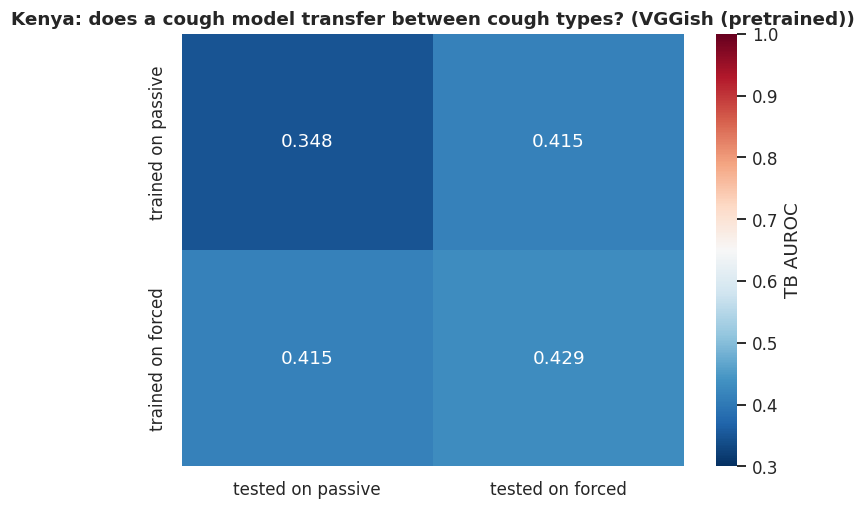

In [13]:
if CFG["LOAD_FORCED"] and (feat.ctype == "forced").any():
    both_s = sorted(set(feat.subject_id[feat.ctype == "passive"]) & set(feat.subject_id[feat.ctype == "forced"]))
    Pb = tb_clin.loc[both_s]
    print(f"Participants with both cough types: {len(Pb)} (TB {int(Pb.label.sum())})")
    if len(Pb) >= 10 and Pb.label.nunique() == 2:
        kf = min(5, int(Pb.label.value_counts().min()))
        fold_b = pd.Series(-1, index=Pb.index)
        for k, (_, te) in enumerate(StratifiedKFold(kf, shuffle=True, random_state=CFG["SEED"]).split(Pb.index, Pb.label)):
            fold_b.iloc[te] = k
        F = FEATS[PRIMARY]; fb = feat[feat.subject_id.isin(both_s)]
        mat = pd.DataFrame(index=["trained on passive", "trained on forced"], columns=["tested on passive", "tested on forced"], dtype=float)
        for tr_t in ("passive", "forced"):
            for te_t in ("passive", "forced"):
                scores = []
                for k in range(kf):
                    te_s, tr_s = fold_b.index[fold_b == k], fold_b.index[fold_b != k]
                    trm = fb.subject_id.isin(tr_s) & (fb.ctype == tr_t); tem = fb.subject_id.isin(te_s) & (fb.ctype == te_t)
                    if not tem.any() or fb.label[trm].nunique() < 2:
                        continue
                    p = probe(F[fb.index[trm]], fb.label[trm].values, F[fb.index[tem]])
                    scores.append(part_mean(fb.subject_id[tem].values, p))
                s = pd.concat(scores); y = Pb.label.reindex(s.index)
                mat.loc[f"trained on {tr_t}", f"tested on {te_t}"] = roc_auc_score(y, s)
        display(mat.round(3)); mat.to_csv(OUT / "kenya_cough_type_transfer.csv")
        ax = sns.heatmap(mat.astype(float), annot=True, fmt=".3f", cmap="RdBu_r", vmin=0.3, vmax=1.0, cbar_kws={"label": "TB AUROC"})
        ax.set_title(f"Kenya: does a cough model transfer between cough types? ({PRIMARY})")
        plt.tight_layout(); plt.show()
    else:
        print("Too few participants with both cough types for this analysis.")
else:
    print("Forced coughs not loaded; skipped.")

## Step 10. Zambia and Kenya: does a model travel between countries?

**What we do.** Put the Zambia coughs through the **identical** front end (each Notebook 01 clip centred in one second of zeros, as TBscreen padded its clips) and the same embedding. Then, with the clinical variables kept in Step 2:
* **Within each country:** five-fold cross-validation, as the reference.
* **Across countries:** train on all of one country, test on all of the other, in both directions.

For each setting we report the questionnaire model (B), audio alone, the combined model (A) and the gain $\Delta$ = A − B. A last check asks how easily a classifier can tell **which country** a cough came from.

**Read with care.** The two datasets differ in country, devices, recording protocol, clip preparation *and* study design (case-control in Kenya, triage in Zambia). A drop across countries shows that transfer fails; it cannot say which of these differences caused it. That limitation is the reason the original study design holds out countries *within* one consistent dataset, CODA.

In [14]:
z_seg_dir = find_input("segmentation_manifest.csv", "segmented", "zambia_segmented", Z_ROOTS) if z_index is not None else None
CROSS = {}
if z_seg_dir is None:
    print("Zambia cough clips not found: Step 10 is skipped.")
else:
    seg_root = z_seg_dir / "segmented_coughs"
    if not seg_root.is_dir():
        seg_root = next(p for p in z_seg_dir.parent.rglob("segmented_coughs") if p.is_dir())
    zf = CACHE / f"zambia_inputs_{len(z_index)}.npy"
    if zf.exists():
        ZX = np.load(zf)
    else:
        def zload(rel):
            w, sr = sf.read(seg_root / rel, dtype="float32")
            return vggish_example_padded(w, sr)
        t0 = time.time()
        with ThreadPoolExecutor(8) as pool:
            ZX = np.stack(list(pool.map(zload, z_index.rel_path))).astype(np.float32)
        np.save(zf, ZX); print(f"Zambia spectrograms computed: {ZX.shape} in {time.time() - t0:.0f} s")
    ZFEATS = {"Spectrogram summary": spectral_summary(ZX)}
    if TORCH_OK:
        ZFEATS["VGGish (pretrained)"] = embed_cached(ZX, f"zambia_{len(z_index)}")
    ZC = z_index.rename(columns={"label": "label"}).reset_index(drop=True)
    ZP = z_clin.loc[sorted(ZC.subject_id.unique())].copy()
    ZP["label"] = ZC.groupby("subject_id").label.first().reindex(ZP.index).astype(int)
    zfold = pd.Series(-1, index=ZP.index)
    for k, (_, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=CFG["SEED"]).split(ZP.index, ZP.label)):
        zfold.iloc[te] = k
    ZP["fold"] = zfold
    CROSS = {"Zambia": (ZP, ZC, ZFEATS[PRIMARY]), "Kenya": (KP, CP, FEATS[PRIMARY][idx_p])}
    print(f"Zambia: {len(ZP)} participants (TB {int(ZP.label.sum())}), {len(ZC):,} clips | "
          f"Kenya: {len(KP)} participants (TB {int(KP.label.sum())}), {len(CP):,} clips | features: {PRIMARY}")

Zambia spectrograms computed: (5287, 96, 64) in 360 s
  embedded 5,287 spectrograms (zambia_5287) in 2 s on cuda
Zambia: 325 participants (TB 57), 5,287 clips | Kenya: 148 participants (TB 102), 32,943 clips | features: VGGish (pretrained)


,setting,test participants,TB,B: questionnaire,audio only,A: questionnaire + audio,gain Δ = A − B,p
0,"Zambia (within, 5-fold)",325,57,0.736,0.675,0.755,+0.019 (-0.01 to +0.04),0.13
1,"Kenya (within, 5-fold)",148,102,0.714,0.711,0.709,-0.006 (-0.04 to +0.03),0.76
2,Zambia → Kenya,148,102,0.660,0.551,0.644,-0.016 (-0.05 to +0.01),0.27
3,Kenya → Zambia,325,57,0.683,0.585,0.679,-0.003 (-0.02 to +0.02),0.74


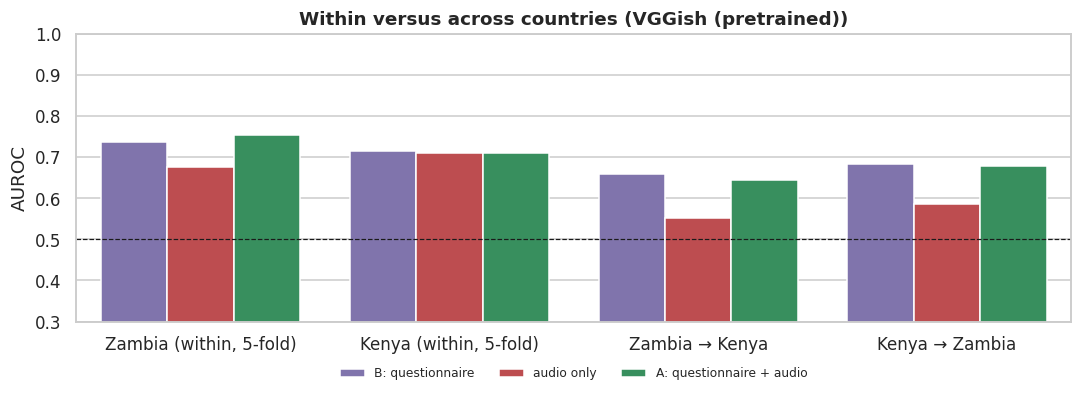

Telling the country apart from one cough (unseen participants): AUROC 0.986


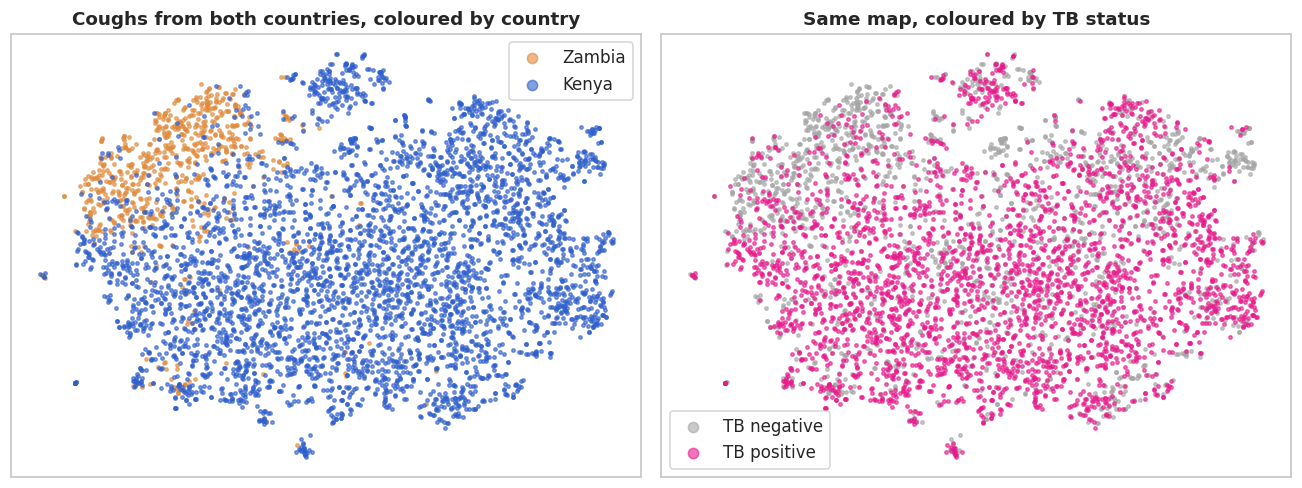

In [15]:
def oof_audio(P, clips, X, k=5):
    out = pd.Series(np.nan, index=P.index)
    k = min(k, int(P.label.value_counts().min()))
    for tr, va in StratifiedKFold(k, shuffle=True, random_state=CFG["SEED"]).split(P.index, P.label):
        mt, mv = clips.subject_id.isin(P.index[tr]).values, clips.subject_id.isin(P.index[va]).values
        out.update(part_mean(clips.subject_id.values[mv], probe(X[mt], clips.label.values[mt], X[mv])))
    return out

def cross_eval(src, dst):
    (PS, CS, XS), (PT, CT, XT) = src, dst
    aT = part_mean(CT.subject_id.values, lr_pipe(CFG["PROBE_C"]).fit(XS, CS.label.values).predict_proba(XT)[:, 1]).reindex(PT.index)
    bT = lr_pipe(CFG["CLIN_C"], impute=True).fit(PS[CLIN_USE], PS.label).predict_proba(PT[CLIN_USE])[:, 1]
    aS = oof_audio(PS, CS, XS)
    A = lr_pipe(CFG["CLIN_C"], impute=True).fit(np.c_[PS[CLIN_USE].values, logit(aS.values)], PS.label)
    AT = A.predict_proba(np.c_[PT[CLIN_USE].values, logit(aT.values)])[:, 1]
    return pd.DataFrame({"label": PT.label.values, "B": bT, "audio": aT.values, "A": AT, "fold": 0}, index=PT.index).dropna()

if CROSS:
    res, preds = [], {}
    for name, (P, Cl, X) in CROSS.items():
        pp_w, _ = run_cv(P, Cl, X, P.fold.values)
        preds[f"{name} (within, 5-fold)"] = pp_w
    preds["Zambia → Kenya"] = cross_eval(CROSS["Zambia"], CROSS["Kenya"])
    preds["Kenya → Zambia"] = cross_eval(CROSS["Kenya"], CROSS["Zambia"])
    for setting, pp_ in preds.items():
        d = delong(pp_.label, pp_.B, pp_.A)
        res.append({"setting": setting, "test participants": len(pp_), "TB": int(pp_.label.sum()),
                    "B: questionnaire": round(roc_auc_score(pp_.label, pp_.B), 3),
                    "audio only": round(roc_auc_score(pp_.label, pp_.audio), 3),
                    "A: questionnaire + audio": round(roc_auc_score(pp_.label, pp_.A), 3),
                    "gain Δ = A − B": f"{d['diff']:+.3f} ({d['lo']:+.2f} to {d['hi']:+.2f})", "p": round(d["p"], 2)})
    cross_table = pd.DataFrame(res); display(cross_table); cross_table.to_csv(OUT / "zambia_kenya_cross.csv", index=False)
    long = cross_table.melt(id_vars="setting", value_vars=["B: questionnaire", "audio only", "A: questionnaire + audio"],
                            var_name="model", value_name="AUROC")
    plt.figure(figsize=(10, 3.8))
    ax = sns.barplot(data=long, x="setting", y="AUROC", hue="model", palette=["#7b6bb5", "#d03a3f", "#2a9d5c"])
    ax.axhline(0.5, color="k", ls="--", lw=0.8); ax.set(ylim=(0.3, 1.0), xlabel="", title=f"Within versus across countries ({PRIMARY})")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
    plt.tight_layout(); plt.show()

    # How easily can a classifier tell the country from a single cough?
    nz, nk = len(CROSS["Zambia"][1]), len(CROSS["Kenya"][1])
    Xd = np.vstack([CROSS["Zambia"][2], CROSS["Kenya"][2]]); yd = np.r_[np.zeros(nz), np.ones(nk)]
    gd = np.r_["0", CROSS["Zambia"][1].subject_id.values, CROSS["Kenya"][1].subject_id.values]
    pd_ = cross_val_predict(lr_pipe(CFG["PROBE_C"]), Xd, yd, cv=cvg, groups=gd, method="predict_proba")[:, 1]
    print(f"Telling the country apart from one cough (unseen participants): AUROC {roc_auc_score(yd, pd_):.3f}")
    sub = rng.choice(len(yd), min(len(yd), 5000), replace=False)
    Zc = TSNE(2, perplexity=min(30, max(5, len(sub) // 4)), init="pca", random_state=CFG["SEED"]).fit_transform(StandardScaler().fit_transform(Xd[sub]))
    lab_all = np.r_[CROSS["Zambia"][1].label.values, CROSS["Kenya"][1].label.values][sub]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    for v, col, lab in ((0, "#e08a3c", "Zambia"), (1, "#2f5fcc", "Kenya")):
        mk = yd[sub] == v; axes[0].scatter(Zc[mk, 0], Zc[mk, 1], s=5, alpha=0.6, color=col, label=lab)
    axes[0].set(title="Coughs from both countries, coloured by country", xticks=[], yticks=[]); axes[0].legend(markerscale=3)
    for v, col, lab in ((0, "#a5a5a5", "TB negative"), (1, "#e8198c", "TB positive")):
        mk = lab_all == v; axes[1].scatter(Zc[mk, 0], Zc[mk, 1], s=5, alpha=0.6, color=col, label=lab)
    axes[1].set(title="Same map, coloured by TB status", xticks=[], yticks=[]); axes[1].legend(markerscale=3)
    plt.tight_layout(); plt.show()

## Step 11. Summary and export

**What we do.** Collect the headline numbers in one table and one JSON file, then zip every table, figure and the cached embeddings into a single bundle, `tbscreen_results.zip`, ready to reuse in later notebooks or to download for the report.

In [16]:
pp, cp = BASE[PRIMARY]
d_base = delong(pp.label, pp.B, pp.A)
summary = {
    "participants (T1 passive)": len(KP), "TB positive": int(KP.label.sum()), "clinical variables used": CLIN_USE,
    "features": PRIMARY, "stored spectrograms verified against audio": AGREE,
    "Kenya B AUROC": round(roc_auc_score(pp.label, pp.B), 3), "Kenya audio AUROC": round(roc_auc_score(pp.label, pp.audio), 3),
    "Kenya A AUROC": round(roc_auc_score(pp.label, pp.A), 3),
    "Kenya gain A-B": f"{d_base['diff']:+.3f} ({d_base['lo']:+.2f} to {d_base['hi']:+.2f}), p={d_base['p']:.2f}",
}
if ft_rows:
    summary["fine-tuned VGGish per cough (published 0.661)"] = round(float(ft.cough_auroc.mean()), 3)
    summary["fine-tuned VGGish per participant (published 0.744)"] = round(float(ft.participant_auroc.mean()), 3)
kp = kenya_probe.set_index("features").loc[PRIMARY]
summary["device recoverable (AUROC)"] = float(kp["device: AUROC"]); summary["TB recoverable per participant (AUROC)"] = float(kp["TB: AUROC per participant"])
if CROSS:
    for _, r in cross_table.iterrows():
        summary[f"{r.setting}: B / audio / A"] = f"{r['B: questionnaire']} / {r['audio only']} / {r['A: questionnaire + audio']}"
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
display(pd.Series(summary, name="value").to_frame())

bundle = WORK / "export" / "tbscreen_results.zip"; bundle.parent.mkdir(exist_ok=True)
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.rglob("*")):
        if f.is_file():
            z.write(f, f"outputs/{f.relative_to(OUT).as_posix()}")
    for f in sorted(CACHE.glob("emb_*.npy")) + sorted(CACHE.glob("tb_index_*.csv")):
        z.write(f, f"embeddings/{f.name}")
print(f"Saved {bundle} ({bundle.stat().st_size / 1e6:.1f} MB)")

,value
participants (T1 passive),148
TB positive,102
clinical variables used,"[age, male, smoker, hiv_pos, prev_tb, cough_da..."
features,VGGish (pretrained)
stored spectrograms verified against audio,True
Kenya B AUROC,0.714
Kenya audio AUROC,0.711
Kenya A AUROC,0.709
Kenya gain A-B,"-0.006 (-0.04 to +0.03), p=0.76"
fine-tuned VGGish per cough (published 0.661),0.658


Saved /kaggle/working/export/tbscreen_results.zip (12.5 MB)


## How to read the results

1. **Pipeline check (Step 7b).** Fine-tuned VGGish should land near 0.66 per cough and 0.74 per participant. If it is far off, check the Step 5 verification before reading anything else.
2. **Does audio add to the questionnaire in Kenya (Step 7)?** Look at $\Delta$ and its interval. Kenya's controls also have respiratory illness, so the questionnaire separates the groups less easily than in a triage population, which gives audio more room than in Zambia.
3. **Is the device effect as strong as in Zambia (Step 8)?** Compare device AUROC with TB AUROC, and the share of same-cough pairs further apart than different-person pairs, with the Zambia values (0.99 against 0.67; 51%).
4. **Do the unseen-device and cough-type results (Steps 8 and 9) show drops?** These are clean, single-factor shifts, unlike the country comparison.
5. **Across countries (Step 10).** If within-country AUROC is clearly higher than across-country AUROC, and the country is easy to tell from one cough, the features carry a strong dataset signature. That is the problem our study targets, now shown directly between two countries.